# Cambios del Script $20/10/26$ — Paso 3c: verificación de los cauces
- ### Ajuste al talweg corregido: un punto solo se corre si en su perpendicular hay un **valle** (mínimo local interior de al menos `RIVER_SNAP_MIN_DEPTH` m). Antes se iba al mínimo de la ventana aunque fuera su borde, y en tramos que cruzan una ladera abierta la línea se corría `RIVER_SNAP_M` ladera abajo
- ### Nueva celda 3c: por cauce, tabla de vértices (lat/lon → UTM → marco del cráter, distancia, rumbo, cota), perfil longitudinal original vs ajustado, profundidad del valle, zoom con curvas de nivel y alertas (subidas, tramos sin valle, tramos largos entre vértices)

# Cambios del Script $17/10/26$ — Paso 3b: cauces del evento 2015 y velocidades de la literatura
- ### Cauces **Correntoso, Pedregoso y Turbio** a partir de vértices (lat, lon): se pasan al marco del cráter, se densifican cada `RIVER_DS` m y se **ajustan al talweg** del DEM (`RIVER_SNAP_M`). El sentido aguas abajo lo decide el DEM
- ### Gráficos: cauces 2015 y rutas de máxima pendiente que drenan a ellos en **amarillo**; el resto de las rutas en **azul**. Los cauces se dibujan también en la animación, el mapa de inundación y la vista 3D
- ### **Restricción blanda de velocidad** (`loss_vel`, peso `lambda_vel`): en el corredor de cada cauce ($\pm$`RIVER_HALF_WIDTH`) y donde la PINN predice lahar ($h >$ `H_VEL_GATE`), penaliza $u_s < v_{min}$ ($u_s$: componente aguas abajo) y $|\mathbf{u}| > v_{max}$. Intervalos por tramo de distancia al cráter en `VEL_INTERVALS`
- ### El gate en $h$ va con `stop_gradient`: la red no puede esquivar la restricción secando el cauce
- ### Log: término `Vel` y fracción del corredor con lahar (`vel_moj`); cada `VEL_REPORT_EVERY` épocas, por cauce, fracción mojada, $u_s$ mediana y % dentro del intervalo (set fijo)
- ### Nueva celda 12b: perfil de velocidad máxima y tiempo de llegada a lo largo de cada cauce vs. el intervalo de la literatura
- ### Sin cambios: ecuaciones, cierres, red, ansatz y escalas de los residuos

# Cambios del Script $12/10/26$ — Pasos 1 y 2 del workflow de correcciones
- ### Paso 1 — Fuente en la cumbre: la IC gaussiana sobre un flanco se reemplaza por un **anillo de fusión alrededor del cráter** ($r$ entre `SRC_R_IN` y `SRC_R_OUT`, volumen `SRC_VOLUME`). Partiendo del reposo, $-g\nabla(h+z_b)$ empuja la masa en todas direcciones y la topografía la reparte entre quebradas: los lahares múltiples salen de las EDP. Opcional: limitar la fuente a sectores (`SRC_SECTORS`)
- ### Paso 2 — Marco de la DEM: origen físico $(0,0)$ en el **cráter**, ejes Este/Norte **sin rotar**; dominio `DOM_X_MIN..DOM_X_MAX` × `DOM_Y_MIN..DOM_Y_MAX` en metros desde el cráter. La red recibe entradas centradas en el centro del dominio y escaladas a $[-1,1]$
- ### Fronteras abiertas en los 4 lados (DEM): se eliminan $h=0$ en $y=\pm L_y/2$ y la pared en $x=0$; se penaliza la entrada de masa $h\,\max(0,-\mathbf{u}\cdot\mathbf{n})$. El balance de volumen cuenta la salida por los 4 lados
- ### Diagnóstico radial (distancia al cráter) y reparto del volumen por octantes (N, NE, …) para ver por qué flancos baja el lahar
- ### Mapa previo con rutas de máxima pendiente desde el anillo (solo inspección: la PINN no las usa)
- ### Sin cambios: ecuaciones, cierres físicos, red, ansatz, pérdidas PDE y entrenamiento (pasos 3 en adelante del workflow)

# Cambios del Script $04/10/26$ — Topografía real (DEM ALOS PALSAR)
- ### Nuevo `TOPO_SCENARIO = 4`: $z_b(x,y)$ sale del DEM ALOS PALSAR 12.5 m generado en `DEM/DEM2.ipynb`
- ### ~~Marco local rotado: $x$ aguas abajo desde el punto de inicio~~ (reemplazado el 12/10/26 por el marco centrado en el cráter)
- ### $z_b$ y $\nabla z_b$ se precalculan en una grilla (DEM suavizado) y se interpolan bilinealmente en TensorFlow
- ### En la EDP de momento $\partial_x H = \partial_x h + \partial_x z_b$, con $\partial_x z_b$ de `grad_zb_fixed` (z_b ya no entra a la cinta)
- ### `S_ref` se calcula desde el DEM (pendiente mediana a lo largo de las rutas de máxima pendiente)
- ### Nuevas figuras: mapa del dominio sobre el DEM y mapa de inundación $h_{max}$ en UTM

# Cambios del Script $22/06/26$
- ### Se agrega un Ansatz con la condicion inicial
- ### Dado el Ansatz se quita $Loss_{ic}$
- ### Cinco Capas ocultas con 72 neuronas y SWISH cada una


In [1]:
# ============================================================
# PINN para lahar por etapas (z_b fijo, sin Exner)
# Aprende: h, u, v, C, p
# ============================================================
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, optimizers #type: ignore
import matplotlib.pyplot as plt
tf.random.set_seed(7)
np.random.seed(7)

I0000 00:00:1792686143.264064   23016 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792686143.838559   23016 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792686146.436395   23016 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# ============================================================
# SELECCIÓN DE TOPOGRAFÍA
# ============================================================
TOPO_SCENARIO = 4 # 1: plano inclinado, 2: valle parabólico, 3: valle convergente, 4: DEM ALOS PALSAR

# --- Solo para TOPO_SCENARIO = 4 (DEM) ---
DEM_PATH = "DEM/villarrica_dem_alos_utm19s.tif"  # GeoTIFF UTM 19S generado con DEM/DEM2.ipynb
# [PASO 2] Origen físico (0, 0) = CRÁTER. Ejes SIN rotar: x = Este - E_cráter, y = Norte - N_cráter [m].
# None -> el cráter es el máximo del DEM suavizado (la cumbre).
# Para fijarlo a mano: CRATER_LON, CRATER_LAT en grados WGS84 (se ignora el máximo del DEM).
CRATER_LON, CRATER_LAT = None, None
# Dominio de la PINN en metros desde el cráter. Puede ser asimétrico (p. ej. alargado hacia el
# norte, hacia Pucón), pero debe caber en el DEM: el GeoTIFF actual cubre ~±11 km del cráter.
DOM_X_MIN, DOM_X_MAX = -10_000.0, 10_000.0   # Oeste (-) / Este (+)
DOM_Y_MIN, DOM_Y_MAX = -5_000.0, 10_000.0   # Sur (-) / Norte (+)
ZB_SMOOTH_M = 50.0      # sigma del suavizado gaussiano del DEM [m] (quita ruido de 12.5 m)
ZB_GRID_M = 25.0        # resolución de la grilla de z_b que usa la PINN [m]

# --- [PASO 1] Fuente del lahar: ANILLO DE FUSIÓN alrededor del cráter (solo DEM) ---
# En 2015 la fuente de lava fundió nieve y hielo de la cumbre y hubo lahares en varios valles.
# La masa inicial se reparte en un anillo y la topografía decide por dónde baja.
SRC_R_IN = 400.0        # [m] borde interior del anillo (fuera del cráter)
SRC_R_OUT = 2000.0      # [m] borde exterior; en este DEM r = 2 km queda a ~2000 m s.n.m.
SRC_EDGE_M = 100.0      # [m] ancho de la transición suave de ambos bordes
SRC_VOLUME = 2.0e7      # [m3] volumen inicial (mismo orden que la IC gaussiana anterior, ~2e7 m3)
SRC_SECTORS = None      # None = anillo completo; o [(rumbo_centro, semiancho), ...] en grados (0 = N, 90 = E)
SRC_SECTOR_EDGE_DEG = 5.0          # [°] transición suave del borde de cada sector
C_SRC_BG, C_SRC_PEAK = 0.35, 0.25  # C0 = C_SRC_BG + C_SRC_PEAK * forma de la fuente

# --- [PASO 3b] Cauces del evento 2015 (solo DEM) ---
# Vértices (lat, lon) en grados WGS84. Se pasan al marco del cráter y se densifican cada RIVER_DS m.
# Con 5-7 vértices la poligonal es una aproximación gruesa del cauce: si RIVER_SNAP_M > 0, cada
# punto se corre al TALWEG (cota mínima del DEM suavizado en una perpendicular de ±RIVER_SNAP_M).
# El sentido aguas abajo lo decide el DEM, así que el orden de los vértices no importa.
RIVERS_LATLON = {
    "Correntoso": [(-39.30290, -72.06799), (-39.33049, -72.05628), (-39.34024, -72.02702),
                   (-39.36393, -72.00696), (-39.38734, -71.98689), (-39.40545, -71.95484)],
    "Pedregoso":  [(-39.30513, -71.88462), (-39.33105, -71.88267), (-39.34916, -71.89019),
                   (-39.37536, -71.89688), (-39.39709, -71.91416)],
    "Turbio":     [(-39.27726, -71.90468), (-39.30262, -71.88880), (-39.31015, -71.87598),
                   (-39.32742, -71.85898), (-39.36198, -71.85898), (-39.38149, -71.87709),
                   (-39.43249, -71.87486)],
}
RIVER_DS = 25.0            # [m] espaciado de los puntos del eje de cada cauce
RIVER_SNAP_M = 200.0       # [m] búsqueda del talweg a cada lado del eje (0 = usar la poligonal tal cual)
RIVER_SNAP_MIN_DEPTH = 3.0 # [m] profundidad mínima del valle para correr un punto; si no hay valle, no se mueve
RIVER_HALF_WIDTH = 150.0   # [m] semiancho del corredor de cada cauce (restricción y gráficos)
RIVER_COLOR = "#FFD400"    # amarillo: cauces 2015 y rutas de máxima pendiente que drenan a ellos
ROUTE_COLOR = "#1f5fbf"    # azul: el resto de las rutas

# --- [PASO 3b] Restricción BLANDA de velocidad en los cauces ---
# Por cauce, lista de tramos (r_min, r_max, v_min, v_max): r = distancia al cráter [m], v en m/s.
# En los puntos del corredor donde la PINN predice lahar (h > H_VEL_GATE) se penaliza
#     u_s < v_min   (u_s = componente de la velocidad AGUAS ABAJO a lo largo del cauce)
#     |u| > v_max
# Dentro del intervalo la pérdida es cero. None = el cauce solo se dibuja, sin restricción.
# >>> REEMPLAZAR CON TUS INTERVALOS. Valor provisorio del Turbio: el pulso inicial del lahar de 2015
# >>> recorrió de ~2 a ~12 km del cráter a ~38 m/s en promedio (Johnson & Palma 2015, GRL 42,
# >>> doi:10.1002/2015GL065024; ellos lo ubican en el drenaje "Correntoso/Turbio": revisa a qué
# >>> valle corresponde en tu trazado). Se usa ±20 %. Correntoso y Pedregoso quedan sin intervalo.
VEL_INTERVALS = {# p. ej. [(2000.0, 10000.0, v_min, v_max)]
    "Correntoso": [(2000.0, 19000.0, 5.0, 20.05)], #Extraido de Tesis erupcion 3 de marzo de la udec pag 86, vmin 12.36 segun ese paper. 4-6 segun avalanchas mixtas 
    "Pedregoso":  [(2000.0, 16000.0, 16.0, 20.0)], #avalanchas mixtas dice que vinit fue 38ms
    "Turbio":     [(2000.0, 12000.0, 30.0, 46.0)],   # Jonson & Palma 2015, GRL 42, doi:10.1002/2015GL065024; ±20 % del promedio de 38 m/s
}
USE_VEL_CONSTRAINT = True
VEL_LOWER = "along"        # "along": v_min se exige a u_s (obliga a bajar por el cauce); "speed": a |u|
H_VEL_GATE = 0.10          # [m] la restricción solo actúa donde h > H_VEL_GATE (hay lahar)
H_VEL_EDGE = 0.03          # [m] ancho de la transición suave del gate
N_VEL = 4096               # puntos del corredor por paso de entrenamiento

# ============================================================
# 1) PARÁMETROS FÍSICOS
# ============================================================
g = 9.81
rho_m = 1800.0
mu0 = 0.20
alpha_C = 1.2
alpha_p = 4.0
C0 = 0.45
p_ref = 1e4
kappa_C = 0.0 #5.0
tau_C = 1e9 # relajación casi nula para C
tau_p = 120.0
chi_p = 0.35 #0.35
# lambda = p/(rho_m g h) inicial. Con mu0=0.2 y pendiente 8% el lahar necesita
# lambda > ~0.29 para que mu_eff < tan(theta); con 0.2 quedaba bloqueado.
lambda_0 = 0.60
# Piso hidrostático: un lahar está SATURADO en agua, así que su presión de poros
# basal nunca baja de la del fluido intersticial, p >= rho_f g h (Iverson 1997).
# En lambda: lambda >= rho_f/rho_m ~ 0.556. Con este piso mu_eff <~ 0.03 < tan(theta)
# en el cuerpo del lahar: el estado "detenido" deja de ser solución de las EDP.
rho_f = 1000.0                   # densidad del fluido intersticial [kg/m3]
lambda_hydro = rho_f / rho_m     # ~0.556
assert lambda_0 >= lambda_hydro, "lambda_0 no puede ser menor que el piso hidrostático"
# Pared impermeable en x = x_min (SOLO escenarios analíticos 1-3): u = 0 exacto
ell_wall = 250.0                 # [m] longitud de la función distancia
# Rampa temporal del ansatz: omega = 1 - exp(-t/t_ramp). Antes era T/5 = 240 s,
# más lenta que la relajación de p (tau_p = 120 s): la red no alcanzaba a acelerar.
t_ramp = 20.0        # [s]
# Resistencia turbulenta de Voellmy: g|u|u/(xi h). Sin ella, con mu_eff < tan(theta)
# el flujo acelera sin límite (a = g(sin - mu cos) = cte).
xi_voellmy = 500.0   # [m/s2]
h_dry = 0.05         # [m] regularización de 1/h en zona seca
# Restricción integral de volumen: V(t) + (volumen que salió por las fronteras) = V0
lambda_vol = 1.0e4
S_ref = 0.08         # pendiente característica (TOPO_SCENARIO = 4: se recalcula desde el DEM)
# Currículo temporal: el horizonte de entrenamiento crece de T_curr0 a Tmax en la etapa 2.
# Primero la red aprende el ARRANQUE (aceleración) y luego lo prolonga en el tiempo.
T_curr0 = 60.0       # [s]
t_early = 120.0      # [s] ventana de arranque sobre-muestreada (25% de cada batch)
u_star = 1.0
C_star = 0.05
eps_u = 1e-3
eps_h = 1e-6
# ============================================================
# 2) DOMINIO
# ============================================================
Tmax = 9000.0
if TOPO_SCENARIO == 4:
    # [PASO 2] Marco centrado en el cráter (celda 3): x Este, y Norte, en metros desde el cráter
    x_min, x_max = DOM_X_MIN, DOM_X_MAX
    y_min, y_max = DOM_Y_MIN, DOM_Y_MAX
else:
    # Escenarios analíticos: canal de 10 km x 2 km con pared en x = 0
    x_min, x_max = 0.0, 10_000.0
    y_min, y_max = -1_000.0, 1_000.0
Lx, Ly = x_max - x_min, y_max - y_min
t_min, t_max = 0.0, Tmax
# Centro del montículo gaussiano (solo escenarios analíticos; con DEM la fuente es el anillo)
IC_X0, IC_Y0 = 1200.0, 0.0
# [PASO 2] Normalización de entradas: el CENTRO DEL DOMINIO va a 0 y los bordes a ±1.
# El cráter es el origen físico; el origen de la red es el centro del dominio. Así las
# entradas quedan simétricas aunque el dominio no esté centrado en el cráter.
x_center, y_center = 0.5 * (x_min + x_max), 0.5 * (y_min + y_max)
x_scale, y_scale = 0.5 * Lx, 0.5 * Ly
t_scale = Tmax
h_scale = 10.0
u_scale = 10.0
p_scale = rho_m * g * h_scale
# Pared en x = x_min solo en el canal analítico; con DEM las 4 fronteras son abiertas
USE_WALL_X0 = TOPO_SCENARIO != 4


In [3]:
# ============================================================
# 3) TOPOGRAFÍA FIJA z_b(x,y)
# ============================================================
# Escenarios 1-3: funciones analíticas. Escenario 4: DEM ALOS PALSAR (DEM/DEM2.ipynb).
#
# [PASO 2] Con el DEM el marco local es una TRASLACIÓN pura de UTM 19S con origen en el cráter:
#   x = Este - E_cráter,  y = Norte - N_cráter   [m]
# Antes el marco se rotaba para alinear x con UNA línea de máxima pendiente y el dominio era
# una franja de 2 km sobre ese cauce: la geometría elegía el río. Ahora ningún rumbo es
# privilegiado y el dominio cubre todos los flancos del cono.
#
# z_b y su gradiente se precalculan en una grilla regular (ZB_GRID_M) desde el DEM suavizado
# (ZB_SMOOTH_M) y se interpolan bilinealmente en TensorFlow. El gradiente NO se obtiene
# derivando la interpolación (sería constante por celda y discontinuo): se interpola la
# grilla del gradiente, así g*dz_b/dx es continuo.

def zb_analytic(x, y):
    if TOPO_SCENARIO == 1:
        # Plano inclinado (Pendiente 10%) - Usar solo para calibrar
        Sx = 0.10
        z0 = 3000.0
        return z0 - Sx * x

    elif TOPO_SCENARIO == 2:
        # Valle Parabólico Suave (Aproximación Villarrica / Quebrada)
        Sx = 0.08         # Pendiente longitudinal (8%)
        z0 = 2900.0       # Altitud base

        # Curvatura del valle.
        # A y=1000m, las paredes suben 50 metros respecto al centro.
        # Esto confina el flujo sin generar gradientes explosivos.
        k_y = 50.0 / (1000.0**2)

        return (z0 - Sx * x) + k_y * (y**2)

    else:
        # Valle Convergente (Embudamiento)
        # El canal se hace más estrecho a medida que se desciende
        Sx = 0.08
        z0 = 2900.0
        # La pendiente transversal aumenta linealmente con 'x'
        k_y = (20.0 + 0.01 * x) / (1000.0**2)
        return (z0 - Sx * x) + k_y * (y**2)


if TOPO_SCENARIO == 4:
    import rasterio
    from pyproj import Transformer
    from scipy.ndimage import gaussian_filter, map_coordinates

    # --- DEM suavizado y su gradiente en UTM ---
    with rasterio.open(DEM_PATH) as src:
        dem = src.read(1).astype(np.float64)
        dem_tr, dem_crs = src.transform, src.crs
    if np.isnan(dem).any():
        raise ValueError(f"{DEM_PATH} tiene píxeles sin dato: regenera el DEM sin allow_nan.")
    # El muestreo de abajo supone un ráster norte-arriba con píxeles cuadrados
    if abs(dem_tr.b) > 1e-9 or abs(dem_tr.d) > 1e-9 or abs(dem_tr.a + dem_tr.e) > 1e-6 * abs(dem_tr.a):
        raise ValueError(f"{DEM_PATH}: se espera un ráster norte-arriba con píxeles cuadrados "
                         f"(transform = {dem_tr}). Reproyéctalo antes de usarlo.")
    dem_res = dem_tr.a
    dem_s = gaussian_filter(dem, ZB_SMOOTH_M / dem_res, mode="nearest")
    dzdE = np.gradient(dem_s, dem_res, axis=1)
    dzdN = -np.gradient(dem_s, dem_res, axis=0)   # las filas crecen hacia el sur

    def dem_sample(A, E, N):
        """Interpola A (grilla del DEM) en coordenadas UTM (E, N). Fuera del DEM -> NaN."""
        E, N = np.asarray(E, dtype=float), np.asarray(N, dtype=float)
        r = (dem_tr.f - N) / dem_res - 0.5
        c = (E - dem_tr.c) / dem_res - 0.5
        out = map_coordinates(A, [r.ravel(), c.ravel()], order=1, mode="constant", cval=np.nan)
        return out.reshape(E.shape)

    # --- [PASO 2] Cráter = origen (0, 0) del marco local ---
    r_top, c_top = np.unravel_index(np.argmax(dem_s), dem.shape)
    E_top = dem_tr.c + (c_top + 0.5) * dem_res
    N_top = dem_tr.f - (r_top + 0.5) * dem_res
    if CRATER_LON is None:
        E_cr, N_cr = float(E_top), float(N_top)
    else:
        E_cr, N_cr = Transformer.from_crs("EPSG:4326", dem_crs, always_xy=True).transform(CRATER_LON, CRATER_LAT)
        E_cr, N_cr = float(E_cr), float(N_cr)
    z_cr = float(dem_sample(dem_s, E_cr, N_cr))

    def local_to_utm(x, y):
        """Marco local (x Este, y Norte, origen en el cráter) -> UTM 19S."""
        return E_cr + np.asarray(x, dtype=float), N_cr + np.asarray(y, dtype=float)

    def utm_to_local(E, N):
        """UTM 19S -> marco local (x Este, y Norte, origen en el cráter)."""
        return np.asarray(E, dtype=float) - E_cr, np.asarray(N, dtype=float) - N_cr

    # Extensión del DEM vista desde el cráter (para validar el dominio)
    dem_x_lo, dem_y_hi = utm_to_local(dem_tr.c, dem_tr.f)
    dem_x_hi = dem_x_lo + dem.shape[1] * dem_res
    dem_y_lo = dem_y_hi - dem.shape[0] * dem_res
    if not (x_min < 0.0 < x_max and y_min < 0.0 < y_max):
        raise ValueError("El cráter (0, 0) debe quedar dentro del dominio [DOM_X_MIN, DOM_X_MAX] x [DOM_Y_MIN, DOM_Y_MAX].")

    # --- Grillas de z_b, dz_b/dx, dz_b/dy en el marco local (con margen en las fronteras) ---
    _m = 2 * ZB_GRID_M
    xg_zb = np.arange(x_min - _m, x_max + _m + 0.5 * ZB_GRID_M, ZB_GRID_M)
    yg_zb = np.arange(y_min - _m, y_max + _m + 0.5 * ZB_GRID_M, ZB_GRID_M)
    XZ, YZ = np.meshgrid(xg_zb, yg_zb, indexing="xy")
    EZ, NZ = local_to_utm(XZ, YZ)
    zb_grid = dem_sample(dem_s, EZ, NZ)
    if np.isnan(zb_grid).any():
        raise ValueError(
            f"El dominio de la PINN se sale del DEM. Desde el cráter, el DEM cubre x en "
            f"[{float(dem_x_lo):.0f}, {float(dem_x_hi):.0f}] m e y en [{float(dem_y_lo):.0f}, {float(dem_y_hi):.0f}] m "
            f"(menos ~{_m + dem_res:.0f} m de margen). Achica DOM_X_MIN/MAX, DOM_Y_MIN/MAX, o agranda "
            "HALF_X_KM / HALF_Y_KM en DEM/DEM2.ipynb y vuelve a guardar el GeoTIFF.")
    # Sin rotación, el gradiente en el marco local ES el gradiente UTM (dz/dE, dz/dN)
    zbx_grid = dem_sample(dzdE, EZ, NZ)
    zby_grid = dem_sample(dzdN, EZ, NZ)

    # --- Rutas de máxima pendiente desde el anillo fuente ---
    # Solo para inspección (celda 3b) y para S_ref: muestran a qué quebradas drena cada parte
    # del anillo. NO restringen a la PINN: por dónde baja el lahar lo deciden las EDP.
    def flow_paths(E0, N0, L, ds):
        """Integra varias líneas de máxima pendiente a la vez. Devuelve (pasos, rutas, 2), NaN al terminar."""
        E, N = np.array(E0, dtype=float), np.array(N0, dtype=float)
        alive = np.ones(E.shape, dtype=bool)
        P = [np.stack([E, N], axis=-1)]
        for _ in range(int(L / ds)):
            gE, gN = dem_sample(dzdE, E, N), dem_sample(dzdN, E, N)
            gn = np.hypot(gE, gN)
            alive &= np.isfinite(gn) & (gn >= 1e-3)        # salió del DEM o llegó a un plano/hoyo
            if not alive.any():
                break
            step = np.where(alive, ds / np.where(alive, gn, 1.0), 0.0)
            E = np.where(alive, E - step * gE, np.nan)
            N = np.where(alive, N - step * gN, np.nan)
            P.append(np.stack([E, N], axis=-1))
        return np.array(P)

    N_SEEDS = 72
    seed_az = np.arange(N_SEEDS) * (360.0 / N_SEEDS)            # rumbo de cada semilla (0 = N)
    seed_r = 0.5 * (SRC_R_IN + SRC_R_OUT)                        # semillas a mitad del anillo
    seed_x, seed_y = seed_r * np.sin(np.radians(seed_az)), seed_r * np.cos(np.radians(seed_az))
    ds_path = 0.5 * dem_res
    _P = flow_paths(*local_to_utm(seed_x, seed_y), 2.0 * max(Lx, Ly), ds_path)
    paths_xy, exits = [], []
    for k in range(N_SEEDS):
        px, py = utm_to_local(_P[:, k, 0], _P[:, k, 1])
        ok = np.isfinite(px) & (px >= x_min) & (px <= x_max) & (py >= y_min) & (py <= y_max)
        n_in = int(np.argmin(ok)) if not ok.all() else ok.size   # hasta que sale del dominio o termina
        paths_xy.append(np.c_[px[:n_in], py[:n_in]])
        if n_in < ok.size and np.isfinite(px[n_in]) and n_in > 0:  # el siguiente punto existe: salió del dominio
            exits.append(paths_xy[-1][-1])
    exits = np.array(exits).reshape(-1, 2)
    # Agrupa las salidas que caen a menos de 500 m entre sí (misma quebrada)
    exit_groups = []
    for e in exits:
        if not any(np.hypot(*(e - q)) < 500.0 for q in exit_groups):
            exit_groups.append(e)
    exit_groups = np.array(exit_groups).reshape(-1, 2)

    # Pendiente característica: mediana de |grad z_b| a lo largo de las rutas, dentro del dominio
    _pp = np.concatenate([p for p in paths_xy if len(p)])
    _pE, _pN = local_to_utm(_pp[:, 0], _pp[:, 1])
    S_ref = float(np.median(np.hypot(dem_sample(dzdE, _pE, _pN), dem_sample(dzdN, _pE, _pN))))

    # --- [PASO 3b] Cauces del evento 2015 ---
    from scipy.spatial import cKDTree
    import matplotlib.patheffects as pe
    _to_dem = Transformer.from_crs("EPSG:4326", dem_crs, always_xy=True)

    def _resample(P, ds):
        """Poligonal P (M, 2) remuestreada a paso uniforme ds. Devuelve (puntos, abscisa curvilínea)."""
        s = np.concatenate([[0.0], np.cumsum(np.hypot(*np.diff(P, axis=0).T))])
        n = max(2, int(np.ceil(s[-1] / ds)) + 1)
        si = np.linspace(0.0, s[-1], n)
        return np.c_[np.interp(si, s, P[:, 0]), np.interp(si, s, P[:, 1])], si

    def _unit_tangents(P):
        T = np.gradient(P, axis=0)
        return T / np.maximum(np.hypot(T[:, 0], T[:, 1]), 1e-9)[:, None]

    def _valley_scan(P):
        """Perfil transversal del DEM suavizado en cada punto de P (±RIVER_SNAP_M).
        Devuelve (desplazamiento al fondo del valle [m], profundidad del valle [m]).
        Profundidad = min(cota máx. a la izquierda, cota máx. a la derecha) - cota del fondo.
        Si el mínimo cae en un borde de la ventana (ladera abierta, sin valle) la profundidad es -inf."""
        T = _unit_tangents(P)
        Nrm = np.c_[-T[:, 1], T[:, 0]]
        step = 0.5 * dem_res
        offs = np.arange(-RIVER_SNAP_M, RIVER_SNAP_M + 0.5 * step, step)
        cand = P[:, None, :] + offs[None, :, None] * Nrm[:, None, :]          # (M, K, 2)
        z = dem_sample(dem_s, *local_to_utm(cand[..., 0], cand[..., 1]))
        fin = np.isfinite(z)
        k = np.argmin(np.where(fin, z + 1e-3 * np.abs(offs)[None, :], np.inf), axis=1)  # empate -> el más cercano
        idx = np.arange(len(offs))[None, :]
        zl = np.where(fin & (idx < k[:, None]), z, -np.inf).max(axis=1)
        zr = np.where(fin & (idx > k[:, None]), z, -np.inf).max(axis=1)
        with np.errstate(invalid="ignore"):
            depth = np.minimum(zl, zr) - z[np.arange(len(P)), k]
        depth[~fin.all(axis=1)] = -np.inf                                         # fuera del DEM
        return offs[k], depth, Nrm

    def _snap_thalweg(P):
        """[PASO 3c] Corre cada punto al fondo del valle SOLO si hay un valle (mínimo local interior con
        profundidad >= RIVER_SNAP_MIN_DEPTH). Antes se corría al mínimo de la ventana aunque fuera su
        borde: en un tramo que cruza una ladera abierta eso desplazaba toda la línea RIVER_SNAP_M
        ladera abajo. Devuelve (puntos ajustados, fracción de puntos que encontró valle)."""
        off, depth, Nrm = _valley_scan(P)
        ok = depth >= RIVER_SNAP_MIN_DEPTH
        shift = np.where(ok, off, 0.0)
        w = max(3, int(RIVER_SNAP_M / RIVER_DS)) | 1                             # media móvil del desplazamiento
        shift = np.convolve(np.pad(shift, w // 2, mode="edge"), np.ones(w) / w, "valid")
        return _resample(P + shift[:, None] * Nrm, RIVER_DS)[0], float(ok.mean())

    RIVERS = {}
    for _name, _pts in RIVERS_LATLON.items():
        _lat, _lon = np.array(_pts, dtype=float).T
        _verts = np.column_stack(utm_to_local(*_to_dem.transform(_lon, _lat)))
        _P = _raw = _resample(_verts, RIVER_DS)[0]
        _snap_frac = np.nan
        if RIVER_SNAP_M > 0:
            _P, _snap_frac = _snap_thalweg(_raw)
        _z = dem_sample(dem_s, *local_to_utm(_P[:, 0], _P[:, 1]))
        _zf = _z[np.isfinite(_z)]
        if _zf.size >= 2 and _zf[0] < _zf[-1]:          # se ordena de aguas arriba a aguas abajo
            _P, _z, _verts, _raw = _P[::-1], _z[::-1], _verts[::-1], _raw[::-1]
        _T = _unit_tangents(_P)                          # tangente unitaria AGUAS ABAJO
        RIVERS[_name] = dict(
            xy=_P, t=_T, n=np.c_[-_T[:, 1], _T[:, 0]], z=_z, verts=_verts, raw=_raw, snap_frac=_snap_frac,
            s=np.concatenate([[0.0], np.cumsum(np.hypot(*np.diff(_P, axis=0).T))]),
            r=np.hypot(_P[:, 0], _P[:, 1]),
            inside=(_P[:, 0] >= x_min) & (_P[:, 0] <= x_max) & (_P[:, 1] >= y_min) & (_P[:, 1] <= y_max),
            tree=cKDTree(_P))

    # Rutas de máxima pendiente que drenan a cada cauce: >= 30 % de sus puntos a < 2*RIVER_HALF_WIDTH
    route_river = []
    for pxy in paths_xy:
        _best, _bf = None, 0.0
        if len(pxy) >= 5:
            for _name, R in RIVERS.items():
                _f = float((R["tree"].query(pxy)[0] < 2.0 * RIVER_HALF_WIDTH).mean())
                if _f > _bf:
                    _best, _bf = _name, _f
        route_river.append(_best if _bf >= 0.3 else None)

    # Distancia de cada nodo de la grilla de z_b al cauce más cercano (para pintar los corredores)
    _q = np.c_[XZ.ravel(), YZ.ravel()]
    river_dist_grid = np.full(XZ.size, np.inf)
    for R in RIVERS.values():
        river_dist_grid = np.minimum(river_dist_grid, R["tree"].query(_q)[0])
    river_dist_grid = river_dist_grid.reshape(XZ.shape)

    _RIV_PE = [pe.Stroke(linewidth=4.0, foreground="k"), pe.Normal()]

    def draw_rivers(a, to_utm=False, labels=True, lw=2.4, verts=False):
        """Dibuja los cauces 2015 en amarillo (marco local, o UTM con to_utm=True)."""
        T = local_to_utm if to_utm else (lambda x, y: (x, y))
        for k, (name, R) in enumerate(RIVERS.items()):
            a.plot(*T(R["xy"][:, 0], R["xy"][:, 1]), "-", color=RIVER_COLOR, lw=lw, path_effects=_RIV_PE,
                   zorder=6, label="cauces 2015" if (k == 0 and labels) else None)
            if verts:
                a.plot(*T(R["verts"][:, 0], R["verts"][:, 1]), "o", mfc=RIVER_COLOR, mec="k", ms=4, zorder=7)
            if labels:
                sel = np.flatnonzero(R["inside"]) if R["inside"].any() else np.arange(len(R["xy"]))
                xl, yl = T(*R["xy"][sel[len(sel) // 2]])
                a.text(float(xl), float(yl), name, fontsize=8, zorder=8, ha="left", va="bottom",
                       bbox=dict(fc=RIVER_COLOR, ec="k", lw=0.5, boxstyle="round,pad=0.2"))

    # --- Interpolación bilineal en TensorFlow ---
    _zb_stack = tf.constant(np.stack([zb_grid, zbx_grid, zby_grid], axis=-1)
                            .reshape(-1, 3).astype(np.float32))
    _gx0, _gy0 = float(xg_zb[0]), float(yg_zb[0])
    _gnx, _gny = len(xg_zb), len(yg_zb)

    def _zb_interp(xm, ym):
        """(z_b, dz_b/dx, dz_b/dy) en puntos (xm, ym) de forma (N, 1). Devuelve (N, 3)."""
        fx = tf.clip_by_value((xm - _gx0) / ZB_GRID_M, 0.0, _gnx - 1.001)
        fy = tf.clip_by_value((ym - _gy0) / ZB_GRID_M, 0.0, _gny - 1.001)
        i0, j0 = tf.floor(fx), tf.floor(fy)
        wx, wy = fx - i0, fy - j0
        idx = tf.cast(j0, tf.int32) * _gnx + tf.cast(i0, tf.int32)
        g = lambda k: tf.reshape(tf.gather(_zb_stack, k), (-1, 3))
        z00, z01 = g(idx), g(idx + 1)
        z10, z11 = g(idx + _gnx), g(idx + _gnx + 1)
        out = (1 - wy) * ((1 - wx) * z00 + wx * z01) + wy * ((1 - wx) * z10 + wx * z11)
        return tf.stop_gradient(out)

    print(f"DEM: {DEM_PATH}  ({dem.shape[0]} x {dem.shape[1]} px, {dem_res:.1f} m)")
    print(f"Cráter (0, 0): E={E_cr:.0f} N={N_cr:.0f} (UTM 19S), z={z_cr:.0f} m "
          f"{'(máximo del DEM suavizado)' if CRATER_LON is None else '(CRATER_LON / CRATER_LAT)'}")
    print(f"Dominio desde el cráter: x en [{x_min:.0f}, {x_max:.0f}] m, y en [{y_min:.0f}, {y_max:.0f}] m "
          f"({Lx / 1e3:.1f} x {Ly / 1e3:.1f} km). El DEM cubre x en [{float(dem_x_lo):.0f}, {float(dem_x_hi):.0f}], "
          f"y en [{float(dem_y_lo):.0f}, {float(dem_y_hi):.0f}] m")
    print(f"z_b en el dominio: {zb_grid.min():.0f} a {zb_grid.max():.0f} m | "
          f"S_ref = {S_ref:.3f} (pendiente mediana de las rutas de máx. pendiente)")
    print(f"Rutas desde el anillo: {N_SEEDS}; salen del dominio por {len(exit_groups)} puntos distintos "
          f"(> 500 m entre sí); {N_SEEDS - len(exits)} terminan dentro (plano u hoyo del DEM)")
    print(f"Cauces 2015 (ajuste al talweg ±{RIVER_SNAP_M:.0f} m; corredor ±{RIVER_HALF_WIDTH:.0f} m):")
    for _name, R in RIVERS.items():
        _ds = np.diff(R["s"], prepend=0.0)
        _zi = R["z"][R["inside"]]
        print(f"  {_name:>10}: largo {R['s'][-1] / 1e3:5.1f} km, dentro del dominio {_ds[R['inside']].sum() / 1e3:5.1f} km"
              + (f" | z {np.nanmax(_zi):.0f} -> {np.nanmin(_zi):.0f} m" if _zi.size else "")
              + f" | rutas de máx. pendiente que drenan a él: {sum(rr == _name for rr in route_river)}"
              + (f" | con valle al ajustar: {100 * R['snap_frac']:.0f} %" if np.isfinite(R['snap_frac']) else ""))
    _all = np.concatenate([R["xy"] for R in RIVERS.values()])
    _sug = (np.floor((_all[:, 0].min() - 500) / 500) * 500, np.ceil((_all[:, 0].max() + 500) / 500) * 500,
            np.floor((_all[:, 1].min() - 500) / 500) * 500, np.ceil((_all[:, 1].max() + 500) / 500) * 500)
    _rq = SRC_R_OUT + 5.0 * SRC_EDGE_M + 500.0       # el anillo fuente debe caber con holgura (celda 4)
    _sug = (min(_sug[0], -_rq), max(_sug[1], _rq), min(_sug[2], -_rq), max(_sug[3], _rq))
    if not all(R["inside"].all() for R in RIVERS.values()):
        _fits = (_sug[0] >= dem_x_lo + _m + dem_res and _sug[1] <= dem_x_hi - _m - dem_res
                 and _sug[2] >= dem_y_lo + _m + dem_res and _sug[3] <= dem_y_hi - _m - dem_res)
        print(f"  ! Parte de los cauces queda fuera del dominio. Para cubrirlos enteros: DOM_X = "
              f"[{_sug[0]:.0f}, {_sug[1]:.0f}], DOM_Y = [{_sug[2]:.0f}, {_sug[3]:.0f}] m "
              + ("(cabe en el DEM)" if _fits else "(NO cabe en el DEM actual: agranda el GeoTIFF en DEM/DEM2.ipynb)"))


if TOPO_SCENARIO != 4:
    RIVERS, route_river = {}, []
    def draw_rivers(*args, **kwargs):
        pass


def zb0_physical(x, y):
    if TOPO_SCENARIO == 4:
        return _zb_interp(x, y)[:, 0:1]
    return zb_analytic(x, y)

def grad_zb_fixed(x, y):
    """
    Gradiente de la topografía fija.
    DEM: interpolado de la grilla precalculada. Analítico: con GradientTape
    (se calcula aparte para evitar NoneType en Graph mode).
    """
    if TOPO_SCENARIO == 4:
        out = _zb_interp(x, y)
        return out[:, 1:2], out[:, 2:3]
    with tf.GradientTape(persistent=True) as tape:
        tape.watch([x, y])
        zb = zb_analytic(x, y)
    zb_x = tape.gradient(zb, x)
    zb_y = tape.gradient(zb, y)
    del tape
    return zb_x, zb_y


DEM: DEM/villarrica_dem_alos_utm19s.tif  (3360 x 3360 px, 12.5 m)
Cráter (0, 0): E=246967 N=5632407 (UTM 19S), z=2840 m (máximo del DEM suavizado)
Dominio desde el cráter: x en [-10000, 10000] m, y en [-5000, 10000] m (20.0 x 15.0 km). El DEM cubre x en [-21056, 20944], y en [-20919, 21081] m
z_b en el dominio: 371 a 2840 m | S_ref = 0.074 (pendiente mediana de las rutas de máx. pendiente)
Rutas desde el anillo: 72; salen del dominio por 6 puntos distintos (> 500 m entre sí); 23 terminan dentro (plano u hoyo del DEM)
Cauces 2015 (ajuste al talweg ±200 m; corredor ±150 m):
  Correntoso: largo  15.9 km, dentro del dominio  12.2 km | z 1758 -> 445 m | rutas de máx. pendiente que drenan a él: 6 | con valle al ajustar: 34 %
   Pedregoso: largo  11.0 km, dentro del dominio   7.9 km | z 1491 -> 491 m | rutas de máx. pendiente que drenan a él: 10 | con valle al ajustar: 44 %
      Turbio: largo  19.7 km, dentro del dominio  12.1 km | z 1888 -> 488 m | rutas de máx. pendiente que drenan a él: 1

W0000 00:00:1792686152.487808   23016 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1792686152.490212   23016 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1792686152.724597   23016 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13209 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070 Ti, pci bus id: 0000:01:00.0, compute capability: 12.0a


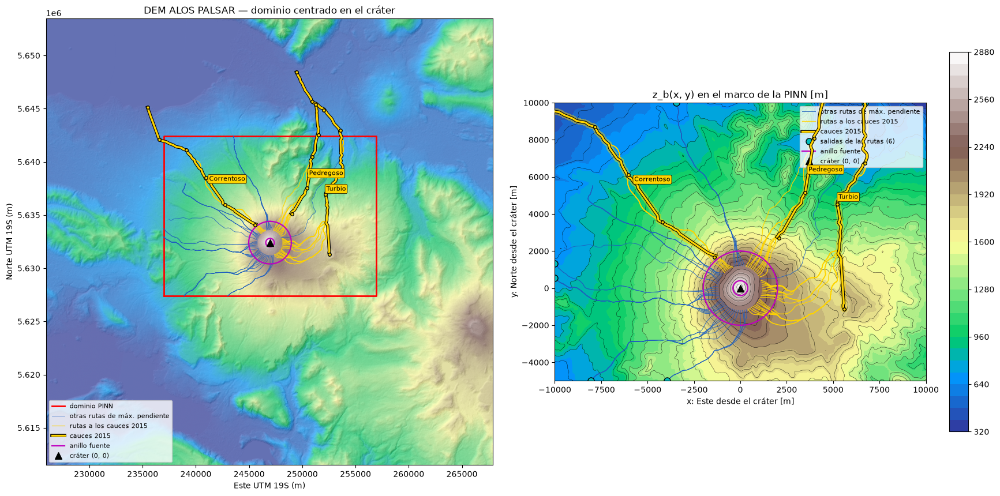

In [4]:
# ============================================================
# 3b) MAPA DEL DOMINIO Y DE LA FUENTE SOBRE EL DEM (solo TOPO_SCENARIO = 4)
# ============================================================
# Revisa aquí, ANTES de entrenar:
#   - el dominio (rojo) contiene el cono y las quebradas de interés;
#   - el anillo fuente (magenta) cae en la zona de nieve/hielo de la cumbre;
#   - las rutas de máxima pendiente muestran a qué quebradas drenará cada parte del anillo:
#     AMARILLAS las que bajan por los cauces 2015 (Correntoso, Pedregoso, Turbio), AZULES el resto.
#     Sus salidas (círculos cian) marcan por dónde dejarían el dominio. La PINN NO usa estas rutas;
#   - los cauces 2015 (amarillo con borde negro, vértices originales como puntos) y su corredor
#     (sombreado) son donde actúa la restricción de velocidad.
if TOPO_SCENARIO == 4:
    from matplotlib.colors import LightSource
    ext_dem = (dem_tr.c, dem_tr.c + dem.shape[1] * dem_res, dem_tr.f - dem.shape[0] * dem_res, dem_tr.f)
    hill_dem = LightSource(azdeg=315, altdeg=45).hillshade(dem, dx=dem_res, dy=dem_res)
    _cx = np.array([x_min, x_max, x_max, x_min, x_min])
    _cy = np.array([y_min, y_min, y_max, y_max, y_min])
    cE, cN = local_to_utm(_cx, _cy)                 # esquinas del dominio en UTM
    _th = np.linspace(0.0, 2.0 * np.pi, 241)
    ring_xy = [(R * np.sin(_th), R * np.cos(_th)) for R in (SRC_R_IN, SRC_R_OUT)]

    def _draw_source(a, to_utm):
        """Anillo fuente (y bordes de sectores, si hay) en coordenadas locales o UTM."""
        T = local_to_utm if to_utm else (lambda x, y: (x, y))
        for k, (rx, ry) in enumerate(ring_xy):
            a.plot(*T(rx, ry), "m-", lw=1.6, label="anillo fuente" if k == 0 else None)
        for az_c, half in (SRC_SECTORS or []):
            for az in (az_c - half, az_c + half):
                s, c = np.sin(np.radians(az)), np.cos(np.radians(az))
                a.plot(*T(np.array([SRC_R_IN * s, SRC_R_OUT * s]), np.array([SRC_R_IN * c, SRC_R_OUT * c])),
                       "m--", lw=1.2)

    fig, ax = plt.subplots(1, 2, figsize=(18, 8.5))
    ax[0].imshow(dem, cmap="terrain", extent=ext_dem)
    ax[0].imshow(hill_dem, cmap="gray", alpha=0.35, extent=ext_dem)
    ax[0].plot(cE, cN, "r-", lw=2, label="dominio PINN")
    _lab = {True: "rutas a los cauces 2015", False: "otras rutas de máx. pendiente"}
    for pxy, rr in zip(paths_xy, route_river):
        _r = rr is not None
        ax[0].plot(*local_to_utm(pxy[:, 0], pxy[:, 1]), "-", color=RIVER_COLOR if _r else ROUTE_COLOR,
                   lw=0.9 if _r else 0.6, alpha=0.9, label=_lab.pop(_r, None))
    draw_rivers(ax[0], to_utm=True, verts=True)
    _draw_source(ax[0], to_utm=True)
    ax[0].plot(E_cr, N_cr, "k^", ms=9, label="cráter (0, 0)")
    ax[0].set_xlim(ext_dem[:2]); ax[0].set_ylim(ext_dem[2:])
    ax[0].set_title("DEM ALOS PALSAR — dominio centrado en el cráter")
    ax[0].set_xlabel("Este UTM 19S (m)"); ax[0].set_ylabel("Norte UTM 19S (m)")
    ax[0].legend(fontsize=8, loc="lower left")

    cs = ax[1].contourf(xg_zb, yg_zb, zb_grid, levels=40, cmap="terrain")
    ax[1].contour(xg_zb, yg_zb, zb_grid, levels=np.arange(0, 3000, 100), colors="k", linewidths=0.3)
    ax[1].contourf(xg_zb, yg_zb, (river_dist_grid < RIVER_HALF_WIDTH).astype(float), levels=[0.5, 1.5],
                   colors=[RIVER_COLOR], alpha=0.45)
    _lab = {True: "rutas a los cauces 2015", False: "otras rutas de máx. pendiente"}
    for pxy, rr in zip(paths_xy, route_river):
        _r = rr is not None
        ax[1].plot(pxy[:, 0], pxy[:, 1], "-", color=RIVER_COLOR if _r else ROUTE_COLOR,
                   lw=1.0 if _r else 0.7, alpha=0.9, label=_lab.pop(_r, None))
    draw_rivers(ax[1], to_utm=False, verts=True)
    if len(exit_groups):
        ax[1].plot(exit_groups[:, 0], exit_groups[:, 1], "o", mfc="c", mec="k", ms=8,
                   label=f"salidas de las rutas ({len(exit_groups)})")
    _draw_source(ax[1], to_utm=False)
    ax[1].plot(0.0, 0.0, "k^", ms=9, label="cráter (0, 0)")
    ax[1].set_xlim(x_min, x_max); ax[1].set_ylim(y_min, y_max); ax[1].set_aspect("equal")
    ax[1].set_title("z_b(x, y) en el marco de la PINN [m]")
    ax[1].set_xlabel("x: Este desde el cráter [m]"); ax[1].set_ylabel("y: Norte desde el cráter [m]")
    ax[1].legend(fontsize=8, loc="upper right")
    plt.colorbar(cs, ax=ax[1], shrink=0.85)
    plt.tight_layout(); plt.show()
else:
    print("TOPO_SCENARIO analítico: no hay mapa del DEM.")


Cráter usado como origen: lat -39.42075, lon -71.93938 | E 246967, N 5632407 | z 2840 m

=== Correntoso (vértices de aguas arriba a aguas abajo) ===
  v       lat        lon        E         N       x       y  r[km]  rumbo   z[m]  tramo[m]
  0 -39.40545  -71.95484   245580   5634062   -1387    1655   2.16   320°   1769       nan
  1 -39.38734  -71.98689   242753   5635981   -4214    3574   5.53   310°   1120      3417  <- tramo largo
  2 -39.36393  -72.00696   240938   5638523   -6029    6115   8.59   315°    795      3123  <- tramo largo
  3 -39.34024  -72.02702   239121   5641095   -7846    8687  11.71   318°    563      3149  <- tramo largo
  4 -39.33049  -72.05628   236562   5642092  -10405    9685  14.21   313°    407      2746  <- tramo largo
  5 -39.30290  -72.06799   235449   5645121  -11518   12713  17.15   318°    228      3227  <- tramo largo
  largo poligonal: 15.7 km  (con DEM: 15.9 km)
  cabecera: r = 2.19 km del cráter, z = 1758 m
  cota: 1758 -> 228 m
  con valle al aju

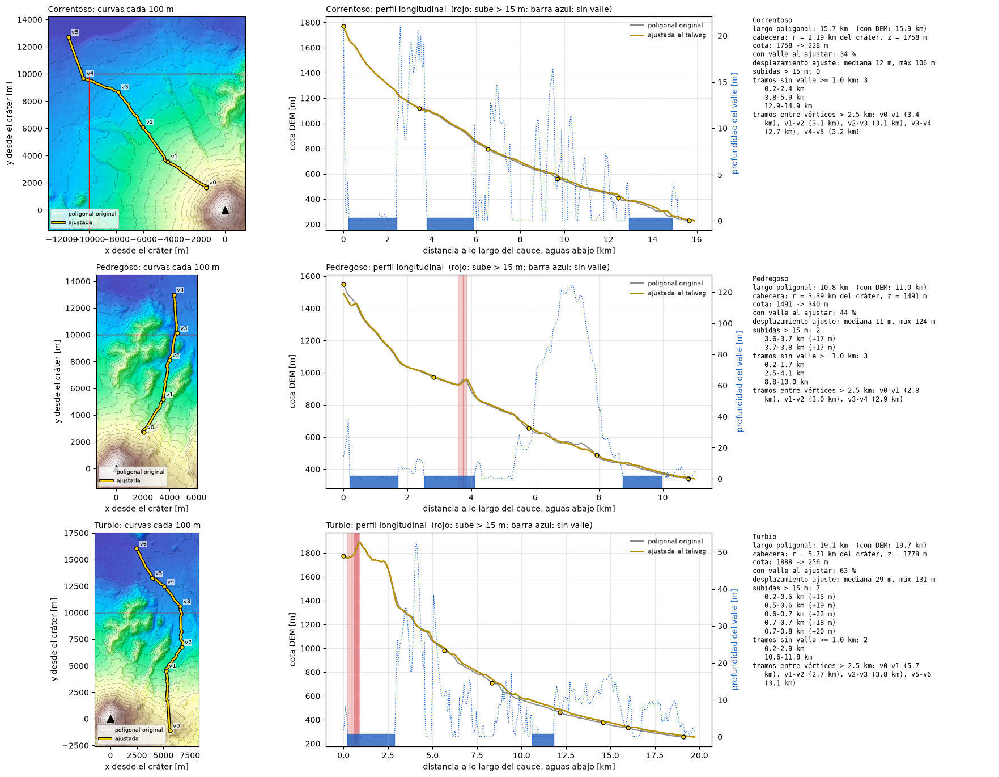

In [5]:
# ============================================================
# 3c) VERIFICACIÓN DE LOS CAUCES 2015 SOBRE EL DEM  [PASO 3c]
# ============================================================
# Para cada cauce:
#   - tabla de vértices: lat/lon -> UTM 19S -> marco del cráter, distancia y rumbo desde el cráter,
#     cota del DEM y largo del tramo (tramos largos sin vértices = poligonal gruesa, revisar)
#   - perfil longitudinal: cota del DEM a lo largo de la poligonal original (gris) y de la ajustada
#     al talweg (amarillo). Un cauce bien trazado BAJA de forma monótona; subidas > CHK_UPHILL_M
#     indican que la línea cruza una loma
#   - profundidad del valle a lo largo del cauce: si es < RIVER_SNAP_MIN_DEPTH en un tramo largo, la
#     línea no va por un valle (ladera abierta o vértices mal puestos)
#   - zoom del mapa con relieve sombreado: poligonal original (blanco punteado) vs ajustada (amarillo)
# Comparación de referencia: cumbre del Villarrica ~(-39.420, -71.939), GVP.
CHK_UPHILL_M = 15.0          # [m] subida (aguas abajo) que se reporta como sospechosa
CHK_LONG_SEG_M = 2500.0      # [m] tramo entre vértices que se reporta como largo
CHK_NO_VALLEY_M = 1000.0     # [m] tramo continuo sin valle que se reporta

if TOPO_SCENARIO == 4 and RIVERS:
    from matplotlib.colors import LightSource
    _to_ll = Transformer.from_crs(dem_crs, "EPSG:4326", always_xy=True)
    lon_cr, lat_cr = _to_ll.transform(E_cr, N_cr)
    print(f"Cráter usado como origen: lat {lat_cr:.5f}, lon {lon_cr:.5f} | E {E_cr:.0f}, N {N_cr:.0f} | z {z_cr:.0f} m")

    def _runs(mask, s):
        """Tramos continuos donde mask es True: lista de (s_ini, s_fin)."""
        out, i0 = [], None
        for i, m in enumerate(np.r_[mask, False]):
            if m and i0 is None:
                i0 = i
            elif not m and i0 is not None:
                out.append((s[i0], s[i - 1])); i0 = None
        return out

    def _uphill_runs(s, z):
        """Tramos donde la cota SUBE aguas abajo más de CHK_UPHILL_M (desde un mínimo previo)."""
        out, zmin, smin = [], np.inf, 0.0
        for si, zi in zip(s, z):
            if not np.isfinite(zi):
                continue
            if zi < zmin:
                zmin, smin = zi, si
            elif zi - zmin > CHK_UPHILL_M:
                out.append((smin, si, zi - zmin)); zmin, smin = zi, si
        return out

    ls = LightSource(azdeg=315, altdeg=45)
    fig, axes = plt.subplots(len(RIVERS), 3, figsize=(18, 4.6 * len(RIVERS)), squeeze=False,
                             gridspec_kw=dict(width_ratios=[1.15, 1.6, 1.0]))
    for row, (name, R) in zip(axes, RIVERS.items()):
        V = R["verts"]
        E_v, N_v = local_to_utm(V[:, 0], V[:, 1])
        lon_v, lat_v = _to_ll.transform(E_v, N_v)
        z_v = dem_sample(dem_s, E_v, N_v)
        print(f"\n=== {name} (vértices de aguas arriba a aguas abajo) ===")
        print(f"{'v':>3} {'lat':>9} {'lon':>10} {'E':>8} {'N':>9} {'x':>7} {'y':>7} {'r[km]':>6} {'rumbo':>6} {'z[m]':>6} {'tramo[m]':>9}")
        for i in range(len(V)):
            seg = np.hypot(*(V[i] - V[i - 1])) if i else np.nan
            rb = (np.degrees(np.arctan2(V[i, 0], V[i, 1])) + 360) % 360
            flag = "  <- tramo largo" if seg > CHK_LONG_SEG_M else ""
            print(f"{i:>3} {lat_v[i]:9.5f} {lon_v[i]:10.5f} {E_v[i]:8.0f} {N_v[i]:9.0f} {V[i, 0]:7.0f} {V[i, 1]:7.0f} "
                  f"{np.hypot(*V[i]) / 1e3:6.2f} {rb:5.0f}° {z_v[i]:6.0f} {seg:9.0f}{flag}")

        # Perfiles: poligonal original y ajustada
        s_raw = np.concatenate([[0.0], np.cumsum(np.hypot(*np.diff(R["raw"], axis=0).T))])
        z_raw = dem_sample(dem_s, *local_to_utm(R["raw"][:, 0], R["raw"][:, 1]))
        _, depth, _ = _valley_scan(R["xy"])
        a = row[1]
        a.plot(s_raw / 1e3, z_raw, "-", color="0.55", lw=1.5, label="poligonal original")
        a.plot(R["s"] / 1e3, R["z"], "-", color="#b38f00", lw=2.0, label="ajustada al talweg")
        s_vert = [s_raw[np.argmin(np.hypot(*(R["raw"] - v).T))] for v in V]
        for sv, zv in zip(s_vert, z_v):
            a.plot(sv / 1e3, zv, "o", mfc=RIVER_COLOR, mec="k", ms=5, zorder=5)
        ups = _uphill_runs(R["s"], R["z"])
        for s0, s1, dz in ups:
            a.axvspan(s0 / 1e3, s1 / 1e3, color="#d03b3b", alpha=0.25)
        nov = [(s0, s1) for s0, s1 in _runs(~(depth >= RIVER_SNAP_MIN_DEPTH) & np.isfinite(R["z"]), R["s"])
               if s1 - s0 >= CHK_NO_VALLEY_M]
        for s0, s1 in nov:
            a.axvspan(s0 / 1e3, s1 / 1e3, ymin=0, ymax=0.06, color="#1f5fbf", alpha=0.8)
        a.set_xlabel("distancia a lo largo del cauce, aguas abajo [km]"); a.set_ylabel("cota DEM [m]")
        a.set_title(f"{name}: perfil longitudinal  (rojo: sube > {CHK_UPHILL_M:.0f} m; barra azul: sin valle)",
                    loc="left", fontsize=10)
        a.grid(alpha=0.25); a.legend(fontsize=8, frameon=False)
        a2 = a.twinx()
        a2.plot(R["s"] / 1e3, np.clip(depth, 0, None), ":", color="#1f5fbf", lw=1)
        a2.set_ylabel("profundidad del valle [m]", color="#1f5fbf")

        # Zoom del mapa
        a = row[0]
        pad = 1500.0
        xs_all = np.r_[R["raw"][:, 0], R["xy"][:, 0], 0.0]; ys_all = np.r_[R["raw"][:, 1], R["xy"][:, 1], 0.0]
        x0, x1 = xs_all.min() - pad, xs_all.max() + pad
        y0, y1 = ys_all.min() - pad, ys_all.max() + pad
        gx = np.arange(x0, x1, 2 * dem_res); gy = np.arange(y1, y0, -2 * dem_res)
        GX, GY = np.meshgrid(gx, gy)
        Zg = dem_sample(dem_s, *local_to_utm(GX, GY))
        Zf = np.where(np.isfinite(Zg), Zg, np.nanmin(Zg))
        a.imshow(ls.shade(Zf, cmap=plt.cm.terrain, vert_exag=2, dx=2 * dem_res, dy=2 * dem_res, blend_mode="soft"),
                 extent=(x0, x1, y0, y1), origin="upper")
        a.contour(GX, GY, Zf, levels=np.arange(0, 3000, 100), colors="k", linewidths=0.3, alpha=0.5)
        a.plot(R["raw"][:, 0], R["raw"][:, 1], "--", color="w", lw=1.4, label="poligonal original")
        a.plot(R["xy"][:, 0], R["xy"][:, 1], "-", color=RIVER_COLOR, lw=2, path_effects=_RIV_PE, label="ajustada")
        a.plot(V[:, 0], V[:, 1], "o", mfc=RIVER_COLOR, mec="k", ms=5, zorder=6)
        for i, v in enumerate(V):
            a.annotate(f"v{i}", v, xytext=(4, 4), textcoords="offset points", fontsize=7,
                       bbox=dict(fc="w", ec="none", alpha=0.7, pad=0.5))
        a.plot(0, 0, "k^", ms=9)
        a.plot(*np.c_[[x_min, x_max, x_max, x_min, x_min], [y_min, y_min, y_max, y_max, y_min]].T, "r-", lw=1)
        a.set_xlim(x0, x1); a.set_ylim(y0, y1); a.set_aspect("equal")
        a.set_title(f"{name}: curvas cada 100 m", loc="left", fontsize=10)
        a.set_xlabel("x desde el cráter [m]"); a.set_ylabel("y desde el cráter [m]")
        a.legend(fontsize=7, loc="lower left")

        # Resumen
        a = row[2]; a.axis("off")
        fin = np.isfinite(R["z"])
        txt = [f"{name}",
               f"largo poligonal: {s_raw[-1] / 1e3:.1f} km  (con DEM: {np.diff(R['s'], prepend=0)[fin].sum() / 1e3:.1f} km)",
               f"cabecera: r = {np.hypot(*R['xy'][0]) / 1e3:.2f} km del cráter, z = {R['z'][fin][0]:.0f} m" if fin.any() else "cabecera fuera del DEM",
               f"cota: {np.nanmax(R['z']):.0f} -> {np.nanmin(R['z']):.0f} m",
               f"con valle al ajustar: {100 * R['snap_frac']:.0f} %" if np.isfinite(R['snap_frac']) else "",
               f"desplazamiento ajuste: mediana {np.median(R['tree'].query(R['raw'])[0]):.0f} m, máx {R['tree'].query(R['raw'])[0].max():.0f} m",
               f"subidas > {CHK_UPHILL_M:.0f} m: {len(ups)}" + "".join(f"\n   {s0/1e3:.1f}-{s1/1e3:.1f} km (+{dz:.0f} m)" for s0, s1, dz in ups[:5]),
               f"tramos sin valle >= {CHK_NO_VALLEY_M / 1e3:.1f} km: {len(nov)}" + "".join(f"\n   {s0/1e3:.1f}-{s1/1e3:.1f} km" for s0, s1 in nov[:5]),
               f"tramos entre vértices > {CHK_LONG_SEG_M / 1e3:.1f} km: "
               + ", ".join(f"v{i-1}-v{i} ({np.hypot(*(V[i] - V[i-1])) / 1e3:.1f} km)" for i in range(1, len(V))
                           if np.hypot(*(V[i] - V[i-1])) > CHK_LONG_SEG_M)]
        import textwrap
        a.text(0, 1, "\n".join("\n".join(textwrap.fill(l, 46, subsequent_indent="   ") for l in t.split("\n"))
                               for t in txt if t), va="top", fontsize=8.5, family="monospace")
        for t in txt[1:]:
            if t:
                print("  " + t.replace("\n", "\n  "))
    plt.tight_layout(); plt.show()
else:
    print("Sin cauces (TOPO_SCENARIO analítico).")


In [6]:
# ============================================================
# 4) CONDICIONES INICIALES
# ============================================================
# [PASO 1] Con DEM, la masa inicial es un ANILLO DE FUSIÓN alrededor del cráter:
#     h0(x, y) = H_SRC * A(r) * S(rumbo),        r = distancia al cráter (0, 0)
#     A(r) = sigmoid((r - R_in)/w) * sigmoid((R_out - r)/w)     anillo con bordes suaves
#     S    = 1 (anillo completo) o unión suave de los sectores SRC_SECTORS
# Parte del reposo (u = v = 0): la fuerza -g grad(h + z_b) empuja la masa cuesta abajo en
# TODAS las direcciones y la topografía la reparte entre las quebradas. Si aparecen lahares
# en varios valles, salen de las EDP de aguas someras, no de cómo se dibujó el dominio.
# Todo es analítico y diferenciable: el ansatz pone h0 dentro de h, así que h_x incluye dh0/dx.
# Los escenarios analíticos (1-3) conservan el montículo gaussiano en (IC_X0, IC_Y0).

def _src_shape(x, y):
    """Forma de la fuente, en [0, 1]. x, y en metros desde el cráter, tensores (N, 1)."""
    r = tf.sqrt(x**2 + y**2 + 1.0)          # +1 m2: sin singularidad en el cráter
    A = tf.math.sigmoid((r - SRC_R_IN) / SRC_EDGE_M) * tf.math.sigmoid((SRC_R_OUT - r) / SRC_EDGE_M)
    if SRC_SECTORS:
        fuera = tf.ones_like(r)             # prod(1 - w_k): vale 1 fuera de todos los sectores
        for az_c, half in SRC_SECTORS:
            sa, ca = float(np.sin(np.radians(az_c))), float(np.cos(np.radians(az_c)))
            cos_half = float(np.cos(np.radians(half)))
            eps = float(np.radians(SRC_SECTOR_EDGE_DEG) * max(np.sin(np.radians(half)), 0.05))
            cos_d = (x * sa + y * ca) / r   # cos(rumbo - az_c) sin atan2: derivable en todo el plano
            fuera = fuera * (1.0 - tf.math.sigmoid((cos_d - cos_half) / eps))
        A = A * (1.0 - fuera)
    return A

if TOPO_SCENARIO == 4:
    # La fuente debe caber entera en el dominio (si no, V0 no sería SRC_VOLUME)
    _d_borde = min(-x_min, x_max, -y_min, y_max)
    if SRC_R_OUT + 5.0 * SRC_EDGE_M > _d_borde:
        raise ValueError(f"El anillo fuente (R_out = {SRC_R_OUT:.0f} m) no cabe en el dominio: "
                         f"la frontera más cercana está a {_d_borde:.0f} m del cráter.")
    # Espesor H_SRC para que el volumen inicial sea SRC_VOLUME (integral numérica a 10 m)
    _R = SRC_R_OUT + 8.0 * SRC_EDGE_M
    _s = np.arange(-_R, _R + 5.0, 10.0, dtype=np.float32)
    _SX, _SY = np.meshgrid(_s, _s)
    _area_src = float(tf.reduce_sum(_src_shape(tf.constant(_SX.reshape(-1, 1)),
                                               tf.constant(_SY.reshape(-1, 1))))) * 10.0**2
    H_SRC = float(SRC_VOLUME / _area_src)
    print(f"Fuente: anillo r = {SRC_R_IN:.0f}-{SRC_R_OUT:.0f} m"
          f"{f', sectores {SRC_SECTORS}' if SRC_SECTORS else ' (completo)'} | área efectiva "
          f"{_area_src / 1e6:.2f} km2 | espesor H_SRC = {H_SRC:.2f} m | volumen {SRC_VOLUME:.2e} m3")

def ic_h_physical(x, y):
    if TOPO_SCENARIO == 4:
        return H_SRC * _src_shape(x, y)
    x0, y0 = IC_X0, IC_Y0
    sigx, sigy = 900.0, 450.0
    h0 = 8.0
    return h0 * tf.exp(-((x - x0)**2 / (2 * sigx**2) + (y - y0)**2 / (2 * sigy**2)))

def ic_u_physical(x, y):
    return tf.zeros_like(x)

def ic_v_physical(x, y):
    return tf.zeros_like(y)

def ic_C_physical(x, y):
    if TOPO_SCENARIO == 4:
        C = C_SRC_BG + C_SRC_PEAK * _src_shape(x, y)
    else:
        C_bg = 0.35 #Minimo
        C_peak = 0.25
        x0, y0 = IC_X0, IC_Y0
        sigx, sigy = 1000.0, 550.0
        C = C_bg + C_peak * tf.exp(-((x - x0)**2 / (2 * sigx**2) + (y - y0)**2 / (2 * sigy**2)))
    return tf.clip_by_value(C, 0.2, 0.75)

def ic_p_physical(x, y):
    return lambda_0 * rho_m * g * ic_h_physical(x, y)


# ============================================================
# 5) MUESTREO DE PUNTOS
# ============================================================
N_ic = 4000
N_pde = 30000
N_bc = 4000

# IC (t=0)
x_ic = tf.random.uniform((N_ic, 1), x_min, x_max, dtype=tf.float32)
y_ic = tf.random.uniform((N_ic, 1), y_min, y_max, dtype=tf.float32)
t_ic = tf.zeros_like(x_ic)

h_ic = ic_h_physical(x_ic, y_ic)
u_ic = ic_u_physical(x_ic, y_ic)
v_ic = ic_v_physical(x_ic, y_ic)
C_ic = ic_C_physical(x_ic, y_ic)
p_ic = ic_p_physical(x_ic, y_ic)

# PDE collocation
# Los puntos PDE se muestrean NUEVOS en cada paso (celda 7, sample_pde_batch):
# horizonte temporal creciente (currículo) + 25% en el arranque [0, t_early].

# BC: puntos en las 4 fronteras (con DEM todas son abiertas: celda 9, loss_bc)
x_bc = tf.random.uniform((N_bc, 1), x_min, x_max, dtype=tf.float32)
t_bc = tf.random.uniform((N_bc, 1), t_min, t_max, dtype=tf.float32)
y_bc_top = tf.ones_like(x_bc) * y_max
y_bc_bot = tf.ones_like(x_bc) * y_min

y_bc = tf.random.uniform((N_bc, 1), y_min, y_max, dtype=tf.float32)
t_bc_x = tf.random.uniform((N_bc, 1), t_min, t_max, dtype=tf.float32)
x_bc_left  = tf.ones_like(y_bc) * x_min
x_bc_right = tf.ones_like(y_bc) * x_max


Fuente: anillo r = 400-2000 m (completo) | área efectiva 12.06 km2 | espesor H_SRC = 1.66 m | volumen 2.00e+07 m3


In [7]:
# ============================================================
# 6) RED NEURONAL: (x,y,t) -> (h,u,v,C) (CON ANSATZ EXACTO)
# ============================================================
Cmax = 0.65

inputs = tf.keras.Input(shape=(3,))
x = layers.Dense(72, activation='swish')(inputs)
x = layers.Dense(72, activation='swish')(x)
x = layers.Dense(72, activation='swish')(x)
x = layers.Dense(72, activation='swish')(x)
x = layers.Dense(72, activation='swish')(x)
x = layers.Dense(72, activation='swish')(x)
#out_raw = layers.Dense(5, activation='linear')(x)
out_raw = layers.Dense(5, activation='linear',
                       kernel_initializer='zeros', bias_initializer='zeros')(x)
#La ultima capa de inicializa con pesos y bias cero para que en la epoca cero la pred sea exacta a la condicion inicial, en nuestro caso el ansantz.
model = tf.keras.Model(inputs=inputs, outputs=out_raw)

lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=1e-3,
    decay_steps=2500,      
    decay_rate=0.5,        
    staircase=False
)
opt = tf.keras.optimizers.Adam(learning_rate=lr_schedule)

@tf.function
def predict_fields(xm, ym, tm):
    # [PASO 2] Entradas centradas: el centro del dominio va a 0 y los bordes a ±1
    xn = (xm - x_center) / x_scale
    yn = (ym - y_center) / y_scale
    tn = tm / t_scale
    inp = tf.concat([xn, yn, tn], axis=1)
    raw = model(inp)

    h_raw = raw[:, 0:1]
    u_raw = raw[:, 1:2]
    v_raw = raw[:, 2:3]
    C_raw = raw[:, 3:4]
    p_raw = raw[:, 4:5]

    h0 = ic_h_physical(xm, ym)
    u0 = ic_u_physical(xm, ym)
    v0 = ic_v_physical(xm, ym)
    p0 = ic_p_physical(xm, ym)
    C0_ic = ic_C_physical(xm, ym)

    omega = 1.0 - tf.exp(-tm / t_ramp)

    if USE_WALL_X0:
        # Canal analítico: pared impermeable en x = x_min. d(x) = 1 - exp(-(x - x_min)/ell)
        # vale 0 en la pared -> flujo h*u = 0
        wall_x = 1.0 - tf.exp(-(xm - x_min) / ell_wall)
        u = u0 + omega * wall_x * (u_raw * u_scale)
    else:
        # [PASO 2] DEM: sin pared. Las 4 fronteras son abiertas (sin entrada de masa: loss_bc)
        u = u0 + omega * (u_raw * u_scale)
    v = v0 + omega * (v_raw * u_scale)

    # Blindaje h: Evitar log(0)
    clip_h = tf.clip_by_value(1.0 - tf.exp(-h0), 1e-7, 1.0)
    inv_sp_h0 = h0 + tf.math.log(clip_h)
    #h = tf.nn.softplus(inv_sp_h0 + omega * h_raw * h_scale)
    h = h0 + omega * h_raw * h_scale

    # p = p_hidrostática(h) + p_exceso, con p_exceso >= 0 (mismo ansatz que h).
    # En t=0: p = rho_f g h0 + (p0 - rho_f g h0) = p0 exacto. Sin techo litostático.
    p_hydro = rho_f * g * h
    pex0_n = (p0 - rho_f * g * h0) / p_scale
    clip_p = tf.clip_by_value(1.0 - tf.exp(-pex0_n), 1e-7, 1.0)
    inv_sp_p0 = pex0_n + tf.math.log(clip_p)
    p = p_hydro + p_scale * tf.nn.softplus(inv_sp_p0 + omega * p_raw)   # Pa

    # Blindaje C: Evitar log(0) con clip_by_value
    C0_norm = tf.clip_by_value(C0_ic / Cmax, 1e-7, 1.0 - 1e-7)
    inv_sig_C0 = tf.math.log(C0_norm / (1.0 - C0_norm))
    C = Cmax * tf.math.sigmoid(inv_sig_C0 + omega * C_raw)

    return h, u, v, C, p

In [8]:
# ============================================================
# 7) CIERRES FÍSICOS
# ============================================================
@tf.function
def mu_eff(C, p, h):
    denom = rho_m*g*h + p_ref
    return mu0*(1.0 + alpha_C*(C - C0)) * tf.exp(-alpha_p * (p/denom))

@tf.function
def cos_theta(zb_x, zb_y):
    return 1.0 / tf.sqrt(1.0 + zb_x**2 + zb_y**2)

@tf.function
def p_eq(h, C, u, v):
    speed = tf.sqrt(u**2 + v**2 + eps_u)
    phiC = C / (C + C_star)
    # En reposo p relaja a la hidrostática (no a cero); el corte genera exceso de presión.
    # lambda_eq va de rho_f/rho_m ~ 0.56 (reposo) a ~0.56 + chi_p*0.44*phiC ~ 0.88 (flujo rápido)
    p_hydro = rho_f * g * h
    p_excess = chi_p * (rho_m - rho_f) * g * h * phiC * (speed / (speed + u_star))
    return p_hydro + p_excess

# ============================================================
# 8) RESIDUOS PDE (SIN Exner, z_b FIJO)
# ============================================================
@tf.function
def pde_residuals(xm, ym, tm):
    # Primer y segundo orden para h,u,v,C,p
    with tf.GradientTape(persistent=True) as tape2:
        tape2.watch([xm, ym, tm])
        with tf.GradientTape(persistent=True) as tape1:
            tape1.watch([xm, ym, tm])

            h, u, v, C, p = predict_fields(xm, ym, tm)
            hu = h * u
            hv = h * v

        # 1er orden
        h_t = tape1.gradient(h, tm)
        hu_x = tape1.gradient(hu, xm)
        hv_y = tape1.gradient(hv, ym)

        u_t = tape1.gradient(u, tm)
        u_x = tape1.gradient(u, xm)
        u_y = tape1.gradient(u, ym)

        v_t = tape1.gradient(v, tm)
        v_x = tape1.gradient(v, xm)
        v_y = tape1.gradient(v, ym)

        h_x = tape1.gradient(h, xm)
        h_y = tape1.gradient(h, ym)

        C_t = tape1.gradient(C, tm)
        C_x = tape1.gradient(C, xm)
        C_y = tape1.gradient(C, ym)

        p_t = tape1.gradient(p, tm)
        p_x = tape1.gradient(p, xm)
        p_y = tape1.gradient(p, ym)

    # 2do orden
    C_xx = tape2.gradient(C_x, xm)
    C_yy = tape2.gradient(C_y, ym)

    del tape1
    del tape2

    # Gradiente topografía fija (separado)
    zb_x, zb_y = grad_zb_fixed(xm, ym)

    # Seguridad extra por si alguna derivada sale None
    if C_xx is None:
        C_xx = tf.zeros_like(xm)
    if C_yy is None:
        C_yy = tf.zeros_like(ym)
    if zb_x is None:
        zb_x = tf.zeros_like(xm)
    if zb_y is None:
        zb_y = tf.zeros_like(ym)

    # Superficie libre H = h + z_b. z_b NO entra a la cinta: su gradiente viene de
    # grad_zb_fixed (analítico, o interpolado de la grilla del DEM, que es continuo).
    H_x = h_x + zb_x
    H_y = h_y + zb_y

    # (1) Masa
    S_h = 0.0
    f_mass = h_t + hu_x + hv_y - S_h

    # Fricción basal
    speed = tf.sqrt(u**2 + v**2 + eps_u)
    mu = mu_eff(C, p, h)
    cth = cos_theta(zb_x, zb_y)

    tau_b = mu * rho_m * g * h * cth
    tau_bx = tau_b * (u / (speed + eps_u))
    tau_by = tau_b * (v / (speed + eps_u))

    # Resistencia turbulenta de Voellmy (aceleración)
    turb_x = g * speed * u / (xi_voellmy * (h + h_dry))
    turb_y = g * speed * v / (xi_voellmy * (h + h_dry))

    # (2) Momento x
    f_momx = u_t + u * u_x + v * u_y + g * H_x + tau_bx / (rho_m * (h + eps_h)) + turb_x

    # (3) Momento y
    f_momy = v_t + u * v_x + v * v_y + g * H_y + tau_by / (rho_m * (h + eps_h)) + turb_y

    # (4) Concentración
    C_eq_val = 0.45
    f_C = C_t + u * C_x + v * C_y - (kappa_C * (C_xx + C_yy) + (C_eq_val - C) / tau_C)
    
    # (5) Presión de poros (advección + relajación)
    peq = p_eq(h, C, u, v)
    f_p = p_t + u*p_x + v*p_y - (peq - p)/tau_p


    return f_mass, f_momx, f_momy, f_C, f_p



In [9]:
# ============================================================
# 9) PÉRDIDAS
# ============================================================
# ============================================================
# PÉRDIDA DE FRONTERA: FRONTERAS ABIERTAS SIN ENTRADA DE MASA  [PASO 2]
# ============================================================
# Antes: h = 0 (Dirichlet) en y = ±Ly/2. Con el DEM eso es una pared artificial que bloquea
# cualquier ruta lateral, y contradecía la IC donde esta tocaba el borde.
# Ahora: el lahar es supercrítico (Fr = |u|/sqrt(g h) > 1). Por una frontera de SALIDA no se
# impone nada (la información sale con el flujo); por una de ENTRADA se impone el estado
# exterior, que es seco. Ambas cosas se cumplen pidiendo que NO ENTRE masa:
#     q_in = h * max(0, -u.n) = 0      (n = normal exterior)
# En el canal analítico la pared x = x_min ya es exacta por el ansatz (u = 0 ahí).
# (Se eliminó el residuo de Neumann de C que se calculaba y descartaba: con kappa_C = 0
#  la ecuación de C es hiperbólica y solo pide dato donde entra flujo, y no entra.)

from sklearn import base


def _inflow_flux(xb, yb, tb, nx_, ny_):
    """Caudal ENTRANTE por unidad de largo h*max(0, -u.n) en puntos de una frontera con normal (nx_, ny_)."""
    h, u, v, _, _ = predict_fields(xb, yb, tb)
    return h * tf.nn.relu(-(u * nx_ + v * ny_))

@tf.function
def loss_bc():
    q_scale = h_scale * u_scale
    q_in = [
        _inflow_flux(x_bc, y_bc_top, t_bc, 0.0, 1.0),          # norte (y = y_max)
        _inflow_flux(x_bc, y_bc_bot, t_bc, 0.0, -1.0),         # sur   (y = y_min)
        _inflow_flux(x_bc_left, y_bc, t_bc_x, -1.0, 0.0),      # oeste (x = x_min)
        _inflow_flux(x_bc_right, y_bc, t_bc_x, 1.0, 0.0),      # este  (x = x_max)
    ]
    return tf.add_n([tf.reduce_mean(tf.square(q / q_scale)) for q in q_in])

@tf.function
def loss_pde_stage2(xb, yb, tb):
    f_mass, f_momx, f_momy, f_C, f_p = pde_residuals(xb, yb, tb)
    eps = 1e-8
    scale_mass = h_scale / t_scale
    # Momento: 10x la escala original u_scale/t_scale. Con la original la red violaba la
    # conservación de volumen (~90%); con g*S (80x) prefería no acelerar.
    scale_mom = 0.1 * g * S_ref
    scale_C = Cmax / t_scale
    scale_p = p_scale / t_scale

    return (
        tf.reduce_mean(tf.square(f_mass / (scale_mass + eps))) +
        tf.reduce_mean(tf.square(f_momx / (scale_mom + eps))) +
        tf.reduce_mean(tf.square(f_momy / (scale_mom + eps))) +
        tf.reduce_mean(tf.square(f_C / (scale_C + eps))) +
        tf.reduce_mean(tf.square(f_p / (scale_p + eps)))
    )

@tf.function
def loss_pde_stage3(xb, yb, tb):
    return loss_pde_stage2(xb, yb, tb)

# ============================================================
# CONSERVACIÓN GLOBAL DE VOLUMEN (restricción integral)  [PASO 2: salida por los 4 lados]
# ============================================================
# f_mass es un residuo LOCAL y blando: la red puede crear masa (versión original,
# masa x8) o destruirla (lahar "evaporado") pagando poco, porque el error se reparte
# en muchos puntos. Integrando la ecuación de masa sobre el dominio:
#     V(t) + int_0^t Q_out dt = V0,   V = int h dA,   Q_out = int_borde h (u.n) ds
# Con las fronteras abiertas, Q_out se integra sobre los 4 lados (antes solo x = Lx).
# Q_out es el caudal NETO (si entrara masa restaría), así que el balance es exacto.
# Pendiente (paso 6 del workflow): nodos fijos en espacio y tiempo.
VOL_DX = 200.0                        # [m] paso de la cuadratura (la fuente tiene bordes de ~SRC_EDGE_M)
nxv = max(50, int(round(Lx / VOL_DX)))
nyv = max(20, int(round(Ly / VOL_DX)))
ntv = 9
_dxv, _dyv = Lx / nxv, Ly / nyv
_xv = (x_min + (np.arange(nxv) + 0.5) * _dxv).astype(np.float32)
_yv = (y_min + (np.arange(nyv) + 0.5) * _dyv).astype(np.float32)
_XV, _YV = np.meshgrid(_xv, _yv)
XV = tf.constant(_XV.reshape(-1, 1)); YV = tf.constant(_YV.reshape(-1, 1))
dA_v = _dxv * _dyv
# Frontera: puntos medios de cada lado (sur, norte, oeste, este) con su normal exterior y su largo
_c32 = lambda a: tf.constant(np.asarray(a, dtype=np.float32).reshape(-1, 1))
XB = _c32(np.concatenate([_xv, _xv, np.full(nyv, x_min), np.full(nyv, x_max)]))
YB = _c32(np.concatenate([np.full(nxv, y_min), np.full(nxv, y_max), _yv, _yv]))
NXB = _c32(np.concatenate([np.zeros(nxv), np.zeros(nxv), -np.ones(nyv), np.ones(nyv)]))
NYB = _c32(np.concatenate([-np.ones(nxv), np.ones(nxv), np.zeros(nyv), np.zeros(nyv)]))
DSB = _c32(np.concatenate([np.full(nxv, _dxv), np.full(nxv, _dxv), np.full(nyv, _dyv), np.full(nyv, _dyv)]))
V0_ref = float(tf.reduce_sum(ic_h_physical(XV, YV)) * dA_v)
print(f"Cuadratura de volumen: {nxv} x {nyv} celdas de {_dxv:.0f} x {_dyv:.0f} m | V0 = {V0_ref:.3e} m3"
      + (f" (SRC_VOLUME = {SRC_VOLUME:.3e}; diferencia {100 * (V0_ref / SRC_VOLUME - 1):+.2f} %)"
         if TOPO_SCENARIO == 4 else ""))

@tf.function
def loss_volume(T_end):
    ts = tf.linspace(0.0, T_end, ntv)
    npv, npb = nxv * nyv, 2 * (nxv + nyv)
    x_all = tf.tile(XV, [ntv, 1]); y_all = tf.tile(YV, [ntv, 1])
    t_all = tf.reshape(tf.repeat(ts, npv), (-1, 1))
    h_v, _, _, _, _ = predict_fields(x_all, y_all, t_all)
    V = tf.reduce_sum(tf.reshape(h_v, (ntv, npv)), axis=1) * dA_v
    xq = tf.tile(XB, [ntv, 1]); yq = tf.tile(YB, [ntv, 1])
    tq = tf.reshape(tf.repeat(ts, npb), (-1, 1))
    h_q, u_q, v_q, _, _ = predict_fields(xq, yq, tq)
    qn = h_q * (u_q * tf.tile(NXB, [ntv, 1]) + v_q * tf.tile(NYB, [ntv, 1])) * tf.tile(DSB, [ntv, 1])
    Q = tf.reduce_sum(tf.reshape(qn, (ntv, npb)), axis=1)      # caudal neto de salida [m3/s]
    dt = ts[1] - ts[0]
    out = tf.concat([[0.0], tf.cumsum(0.5 * (Q[1:] + Q[:-1]) * dt)], axis=0)
    return tf.reduce_mean(tf.square((V + out - V0_ref) / V0_ref))


Cuadratura de volumen: 100 x 75 celdas de 200 x 200 m | V0 = 2.000e+07 m3 (SRC_VOLUME = 2.000e+07; diferencia +0.00 %)


In [10]:
# ============================================================
# 9a) RESTRICCIÓN BLANDA DE VELOCIDAD EN LOS CAUCES 2015  [PASO 3b]
# ============================================================
# Pérdida (restricción de INTERVALO: dentro de [v_min, v_max] no aporta nada):
#   L_vel = sum_i w_i [ relu(v_min - u_s) + relu(|u| - v_max) ]^2 / u_scale^2  /  (sum_i w_i + 1)
#   w_i   = stop_gradient( sigmoid((h_i - H_VEL_GATE) / H_VEL_EDGE) )
#   u_s   = u . t   (t = tangente unitaria del cauce, aguas abajo)
# - Los puntos se muestrean en el corredor de cada cauce (±RIVER_HALF_WIDTH del eje), en los tramos de
#   VEL_INTERVALS y fuera del anillo fuente (ahí el lahar parte del reposo). t es uniforme en [0, T_cur],
#   así que sigue al currículo.
# - El gate w deja actuar la restricción solo donde la PINN ya predice lahar: antes de que llegue el
#   frente, la velocidad en un cauce seco no significa nada (y forzarla chocaría con Voellmy).
# - stop_gradient en w: el gradiente no pasa por h, así la red no puede "esquivar" la restricción
#   secando el cauce. La restricción solo empuja (u, v).
# - Un intervalo medido es la velocidad de un FRENTE o un promedio entre dos puntos; aquí se compara
#   con la velocidad local de la PINN en todo el cuerpo mojado. Es una aproximación: si la red no
#   alcanza el intervalo, revisa primero la física (ver la velocidad terminal impresa abajo).
VEL_POOL_PER_RIVER = 50_000
VEL_SEED = 31
_vel_rows, _vel_rid, VEL_RIVERS = [], [], []
if TOPO_SCENARIO == 4 and USE_VEL_CONSTRAINT:
    _rng_vel = np.random.default_rng(VEL_SEED)
    r_vel_min = SRC_R_OUT + 2.0 * SRC_EDGE_M
    print(f"Restricción de velocidad (corredor ±{RIVER_HALF_WIDTH:.0f} m, gate h > {H_VEL_GATE:.2f} m, "
          f"mínimo sobre {'u_s aguas abajo' if VEL_LOWER == 'along' else '|u|'}, r >= {r_vel_min:.0f} m):")
    for name, R in RIVERS.items():
        segs = VEL_INTERVALS.get(name)
        if not segs:
            print(f"  {name:>10}: sin intervalo (solo se dibuja)")
            continue
        M = len(R["xy"])
        i = _rng_vel.integers(0, M, VEL_POOL_PER_RIVER)
        off = _rng_vel.uniform(-RIVER_HALF_WIDTH, RIVER_HALF_WIDTH, VEL_POOL_PER_RIVER)
        xy = R["xy"][i] + off[:, None] * R["n"][i]
        rr = np.hypot(xy[:, 0], xy[:, 1])
        ok = ((xy[:, 0] >= x_min) & (xy[:, 0] <= x_max) & (xy[:, 1] >= y_min) & (xy[:, 1] <= y_max)
              & (rr >= r_vel_min))
        vmin = np.full(VEL_POOL_PER_RIVER, np.nan); vmax = np.full(VEL_POOL_PER_RIVER, np.nan)
        for r0, r1, v0, v1 in segs:
            assert 0.0 <= v0 < v1, f"{name}: intervalo inválido ({v0}, {v1})"
            sel = ok & (rr >= r0) & (rr < r1)
            vmin[sel], vmax[sel] = v0, v1
        keep = np.isfinite(vmin)
        if not keep.any():
            print(f"  {name:>10}: ningún tramo de {segs} cae dentro del dominio: sin restricción")
            continue
        rid = len(VEL_RIVERS); VEL_RIVERS.append(name)
        _vel_rows.append(np.c_[xy[keep], R["t"][i[keep]], vmin[keep], vmax[keep]])
        _vel_rid.append(np.full(int(keep.sum()), rid))
        # Velocidad terminal de Voellmy en el tramo: g S = g u^2/(xi h)  ->  u_T = sqrt(xi h S)
        # (cota superior: ignora la fricción de Coulomb). Si u_T < v_min, la ecuación de momento y la
        # restricción se contradicen y la red tendrá que violar una de las dos.
        for r0, r1, v0, v1 in segs:
            c = R["inside"] & (R["r"] >= max(r0, r_vel_min)) & (R["r"] < r1)
            if not c.any():
                continue
            E_c, N_c = local_to_utm(R["xy"][c, 0], R["xy"][c, 1])
            S_c = float(np.nanmedian(np.hypot(dem_sample(dzdE, E_c, N_c), dem_sample(dzdN, E_c, N_c))))
            uT = {hh: np.sqrt(xi_voellmy * hh * S_c) for hh in (1.0, 2.0, 5.0)}
            print(f"  {name:>10}: r {r0 / 1e3:.1f}-{r1 / 1e3:.1f} km -> [{v0:.0f}, {v1:.0f}] m/s | {int(keep.sum())} puntos | "
                  f"pendiente mediana {S_c:.3f} | u_T Voellmy (xi={xi_voellmy:.0f}) h=1/2/5 m: "
                  + "/".join(f"{uT[hh]:.0f}" for hh in uT) + " m/s"
                  + ("   <-- u_T < v_min incluso con h=5 m" if uT[5.0] < v0 else ""))

VEL_ACTIVE = len(_vel_rows) > 0
if VEL_ACTIVE:
    VEL_POOL_NP = np.concatenate(_vel_rows).astype(np.float32)     # columnas: x, y, tx, ty, v_min, v_max
    VEL_POOL_RID = np.concatenate(_vel_rid)
    VEL_POOL = tf.constant(VEL_POOL_NP)
    N_VEL_POOL = VEL_POOL_NP.shape[0]
    # Set FIJO para la validación (mismos puntos y tiempos siempre)
    _rng_vv = np.random.default_rng(VEL_SEED + 1)
    _iv = _rng_vv.choice(N_VEL_POOL, size=min(N_VEL, N_VEL_POOL), replace=False)
    VAL_VEL_NP, VAL_VEL_RID = VEL_POOL_NP[_iv], VEL_POOL_RID[_iv]
    VAL_VEL_T = _rng_vv.uniform(0.0, Tmax, (len(_iv), 1)).astype(np.float32)
    _val_vel = tuple(tf.constant(VAL_VEL_NP[:, k:k + 1]) for k in range(6)) + (tf.constant(VAL_VEL_T),)
    print(f"  Pool de la restricción: {N_VEL_POOL} puntos en {', '.join(VEL_RIVERS)} | validación fija: {len(_iv)}")
else:
    print("Restricción de velocidad INACTIVA (sin intervalos dentro del dominio o USE_VEL_CONSTRAINT = False)")


def _vel_terms(xb, yb, tb, tx, ty, vmin, vmax):
    """L_vel, fracción mojada y campos (h, u_s, |u|) en puntos del corredor."""
    h, u, v, _, _ = predict_fields(xb, yb, tb)
    w = tf.stop_gradient(tf.clip_by_value((h - H_VEL_GATE) / H_VEL_EDGE, 0.0, 1.0))
    speed = tf.sqrt(u**2 + v**2 + eps_u)
    u_s = u * tx + v * ty
    low = u_s if VEL_LOWER == "along" else speed
    viol = (tf.nn.relu(vmin - low) + tf.nn.relu(speed - vmax)) / u_scale
    L = tf.reduce_sum(w * tf.square(viol)) / (tf.reduce_sum(w) + 1.0)
    return L, tf.reduce_mean(w), h, u_s, speed

@tf.function
def loss_vel(T_end):
    """(L_vel, fracción de puntos del corredor con lahar) sobre un lote nuevo de N_VEL puntos."""
    if not VEL_ACTIVE:
        return tf.constant(0.0), tf.constant(0.0)
    idx = tf.random.uniform((N_VEL,), 0, N_VEL_POOL, dtype=tf.int32)
    P = tf.gather(VEL_POOL, idx)
    tb = tf.random.uniform((N_VEL, 1)) * T_end
    L, wet, _, _, _ = _vel_terms(P[:, 0:1], P[:, 1:2], tb, P[:, 2:3], P[:, 3:4], P[:, 4:5], P[:, 5:6])
    return L, wet

@tf.function
def _val_vel_terms():
    xb, yb, tx, ty, vmin, vmax, tb = _val_vel
    return _vel_terms(xb, yb, tb, tx, ty, vmin, vmax)

def vel_validation_stats():
    """Sobre el set fijo: L_vel y, por cauce, fracción mojada, u_s mediana y % dentro del intervalo."""
    if not VEL_ACTIVE:
        return {"Vel": 0.0}
    L, _, h, us, sp = _val_vel_terms()
    h, us, sp = h.numpy().ravel(), us.numpy().ravel(), sp.numpy().ravel()
    vmin, vmax = VAL_VEL_NP[:, 4], VAL_VEL_NP[:, 5]
    low = us if VEL_LOWER == "along" else sp
    wet = h > H_VEL_GATE
    out = {"Vel": float(L)}
    for k, name in enumerate(VEL_RIVERS):
        sel = VAL_VEL_RID == k
        sw = sel & wet
        out[f"vel_{name}_mojado"] = float(sw.sum() / max(sel.sum(), 1))
        out[f"vel_{name}_us_mediana"] = float(np.median(us[sw])) if sw.any() else np.nan
        out[f"vel_{name}_en_rango"] = float(((low[sw] >= vmin[sw]) & (sp[sw] <= vmax[sw])).mean()) if sw.any() else np.nan
    return out


Restricción de velocidad (corredor ±150 m, gate h > 0.10 m, mínimo sobre u_s aguas abajo, r >= 2200 m):
  Correntoso: r 2.0-19.0 km -> [5, 20] m/s | 38451 puntos | pendiente mediana 0.102 | u_T Voellmy (xi=500) h=1/2/5 m: 7/10/16 m/s
   Pedregoso: r 2.0-16.0 km -> [16, 20] m/s | 36112 puntos | pendiente mediana 0.105 | u_T Voellmy (xi=500) h=1/2/5 m: 7/10/16 m/s
      Turbio: r 2.0-12.0 km -> [30, 46] m/s | 30532 puntos | pendiente mediana 0.130 | u_T Voellmy (xi=500) h=1/2/5 m: 8/11/18 m/s   <-- u_T < v_min incluso con h=5 m
  Pool de la restricción: 105095 puntos en Correntoso, Pedregoso, Turbio | validación fija: 4096


In [11]:
# ============================================================
# 10) ENTRENAMIENTO POR ETAPAS (Sin Etapa 1)
# ============================================================
pde_batch = 4096
# [PASO 3b] Restricción blanda de velocidad (celda 9a): L += lambda_vel * L_vel.
# "vel_moj" en el log = fracción de puntos del corredor con lahar: mientras sea ~0 la restricción
# no actúa (el frente aún no llega a los cauces). Cada VEL_REPORT_EVERY épocas se imprime, por cauce,
# la fracción mojada, la u_s mediana y el % dentro del intervalo sobre un set fijo de puntos.
VEL_REPORT_EVERY = 500

def _report_vel(ep_global):
    if not VEL_ACTIVE:
        return
    st = vel_validation_stats()
    print(f"    [velocidad, época {ep_global}] L_vel(set fijo) {st['Vel']:.2e} | " + "  ".join(
        f"{n}: mojado {100 * st[f'vel_{n}_mojado']:.1f} %, u_s mediana {st[f'vel_{n}_us_mediana']:.1f} m/s, "
        f"en rango {100 * st[f'vel_{n}_en_rango']:.0f} %" for n in VEL_RIVERS))

# Horizonte temporal actual del currículo (Variable: cambiarlo no re-traza el tf.function)
T_cur = tf.Variable(T_curr0, dtype=tf.float32, trainable=False)

def sample_pde_batch():
    # Puntos nuevos en cada paso: 75% uniformes en [0, T_cur], 25% en el arranque
    n_e = pde_batch // 4
    xb = tf.random.uniform((pde_batch, 1), x_min, x_max)
    yb = tf.random.uniform((pde_batch, 1), y_min, y_max)
    tb = tf.concat([tf.random.uniform((pde_batch - n_e, 1)) * T_cur,
                    tf.random.uniform((n_e, 1)) * tf.minimum(T_cur, t_early)], axis=0)
    return xb, yb, tb

# -------- ETAPA 2 (Ahora es tu inicio de entrenamiento) --------
epochs_stage2 = 3000
lambda_bc_2 = 0.5
lambda_pde_2 = 1.0
lambda_vel_2 = 0.5     # [PASO 3b] peso de la restricción de velocidad

@tf.function
def train_step_stage2():
    xb, yb, tb = sample_pde_batch()

    with tf.GradientTape() as tape:
        Lbc = loss_bc()
        Lpde = loss_pde_stage2(xb, yb, tb)
        Lvol = loss_volume(T_cur)
        Lvel, wet_vel = loss_vel(T_cur)            # [PASO 3b]
        L = lambda_bc_2 * Lbc + lambda_pde_2 * Lpde + lambda_vol * Lvol + lambda_vel_2 * Lvel

    grads = tape.gradient(L, model.trainable_variables)
    opt.apply_gradients(zip(grads, model.trainable_variables))
    
    return L, Lbc, Lpde, Lvol, Lvel, wet_vel

print("\n==============================")
print("ETAPA 2: Ajuste de BC + Masa/Momento")
print("==============================")
for ep in range(epochs_stage2):
    # Currículo: el horizonte crece linealmente de T_curr0 a Tmax en el 80% de la etapa 2
    T_cur.assign(T_curr0 + (Tmax - T_curr0) * min(1.0, ep / (0.8 * epochs_stage2)))
    L, Lbc, Lpde, Lvol, Lvel, wet_vel = train_step_stage2()
    if (ep + 1) % 100 == 0:
        print(f"[Stage 2] Epoch {ep+1}/{epochs_stage2} | T_cur {T_cur.numpy():6.0f} s | Total {L.numpy():.3e} | BC {Lbc.numpy():.3e} | PDE {Lpde.numpy():.3e} | Vol {Lvol.numpy():.2e} | Vel {Lvel.numpy():.2e} (vel_moj {wet_vel.numpy():.2f})")
    if (ep + 1) % VEL_REPORT_EVERY == 0:
        _report_vel(ep + 1)

# -------- ETAPA 3 --------
epochs_stage3 = 3000
lambda_bc_3 = 0.7
lambda_pde_3 = 2
lambda_vel_3 = 0.7

@tf.function
def train_step_stage3():
    xb, yb, tb = sample_pde_batch()

    with tf.GradientTape() as tape:
        Lbc = loss_bc()
        Lpde = loss_pde_stage3(xb, yb, tb)
        Lvol = loss_volume(T_cur)
        Lvel, wet_vel = loss_vel(T_cur)            # [PASO 3b]
        L = lambda_bc_3 * Lbc + lambda_pde_3 * Lpde + lambda_vol * Lvol + lambda_vel_3 * Lvel

    grads = tape.gradient(L, model.trainable_variables)
    opt.apply_gradients(zip(grads, model.trainable_variables))
    
    return L, Lbc, Lpde, Lvol, Lvel, wet_vel

print("\n==============================")
print("ETAPA 3: BC + PDE Completas (Exigencia máxima)")
print("==============================")
T_cur.assign(Tmax)
for ep in range(epochs_stage3):
    L, Lbc, Lpde, Lvol, Lvel, wet_vel = train_step_stage3()
    if (ep + 1) % 100 == 0:
        print(f"[Stage 3] Epoch {ep+1}/{epochs_stage3} | Total {L.numpy():.3e} | BC {Lbc.numpy():.3e} | PDE {Lpde.numpy():.3e} | Vol {Lvol.numpy():.2e} | Vel {Lvel.numpy():.2e} (vel_moj {wet_vel.numpy():.2f})")
    if (ep + 1) % VEL_REPORT_EVERY == 0:
        _report_vel(epochs_stage2 + ep + 1)

print("\nEntrenamiento completado. ¡Tu Condición Inicial está intacta por construcción!")


ETAPA 2: Ajuste de BC + Masa/Momento
[Stage 2] Epoch 100/3000 | T_cur    429 s | Total 2.137e+04 | BC 0.000e+00 | PDE 1.335e+03 | Vol 2.00e+00 | Vel 5.12e-01 (vel_moj 0.02)
[Stage 2] Epoch 200/3000 | T_cur    801 s | Total 2.170e+04 | BC 4.035e-12 | PDE 1.434e+03 | Vol 2.03e+00 | Vel 5.78e-01 (vel_moj 0.01)
[Stage 2] Epoch 300/3000 | T_cur   1174 s | Total 2.163e+04 | BC 8.503e-11 | PDE 1.510e+03 | Vol 2.01e+00 | Vel 3.47e-01 (vel_moj 0.01)
[Stage 2] Epoch 400/3000 | T_cur   1546 s | Total 1.933e+04 | BC 7.034e-07 | PDE 1.702e+03 | Vol 1.76e+00 | Vel 2.55e-01 (vel_moj 0.01)
[Stage 2] Epoch 500/3000 | T_cur   1919 s | Total 1.350e+04 | BC 6.147e-06 | PDE 1.983e+03 | Vol 1.15e+00 | Vel 2.20e-01 (vel_moj 0.01)
    [velocidad, época 500] L_vel(set fijo) 2.12e-01 | Correntoso: mojado 6.2 %, u_s mediana 0.5 m/s, en rango 0 %  Pedregoso: mojado 0.0 %, u_s mediana nan m/s, en rango nan %  Turbio: mojado 0.6 %, u_s mediana 0.8 m/s, en rango 0 %
[Stage 2] Epoch 600/3000 | T_cur   2291 s | Total

Error máximo de la condición inicial:
  |h_real - h_PINN|_inf = 2.384e-07 m      OK (ansatz duro)
  |C_real - C_PINN|_inf = 5.960e-08        OK (ansatz duro)
  |p_real - p_PINN|_inf = 1.766e-02 Pa     OK

  lambda = p/(rho*g*h) en t=0 (zona mojada h>0.1 m):  min=0.600  mediana=0.600  max=0.600
  lambda deseado por ic_p_physical: 0.600 (uniforme)
  fracción de la zona mojada con lambda > 1 (físicamente imposible): 0.0%

  Zona mojada (h>0.1 m) con mu_eff < tan(theta) en t=0: 99.9%   (mu_eff mediano 0.040 vs tan(theta) 0.403)


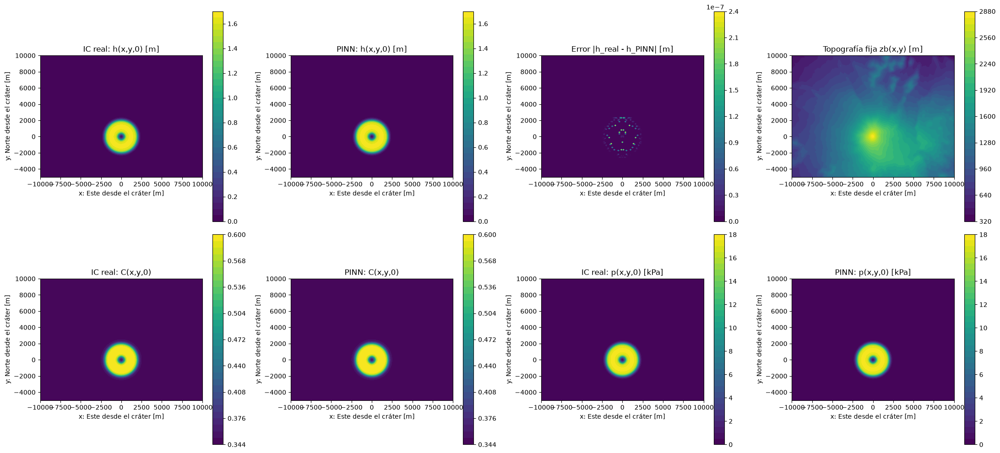

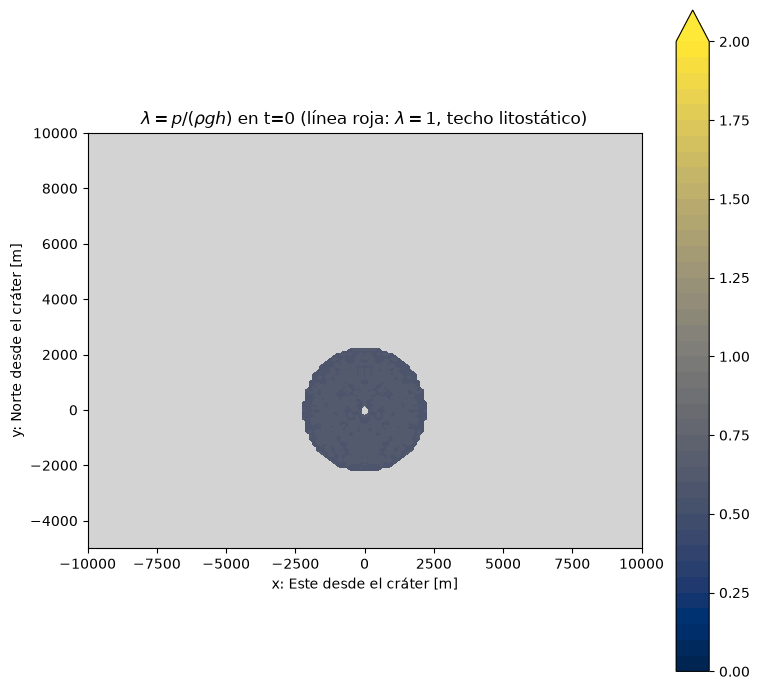

In [12]:
# ============================================================
# 11) VERIFICACIÓN DE CONDICIÓN INICIAL  (h, C y AHORA TAMBIÉN p)
# ============================================================
# Grilla de evaluación (la usan también las celdas 12-14). Con DEM el dominio es ~cuadrado.
if TOPO_SCENARIO == 4:
    nx = ny = 161
    XLAB, YLAB = "x: Este desde el cráter [m]", "y: Norte desde el cráter [m]"
else:
    nx, ny = 120, 80
    XLAB, YLAB = "x [m]", "y [m]"
xg = np.linspace(x_min, x_max, nx).astype(np.float32)
yg = np.linspace(y_min, y_max, ny).astype(np.float32)
X, Y = np.meshgrid(xg, yg, indexing='xy')

Xf = X.reshape(-1, 1)
Yf = Y.reshape(-1, 1)
T0 = np.zeros_like(Xf, dtype=np.float32)

h_pred0, u_pred0, v_pred0, C_pred0, p_pred0 = predict_fields(
    tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf), tf.convert_to_tensor(T0))

h0_map_pred = h_pred0.numpy().reshape(ny, nx)
C0_map_pred = C_pred0.numpy().reshape(ny, nx)
p0_map_pred = p_pred0.numpy().reshape(ny, nx)
zb_map = zb0_physical(tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf)).numpy().reshape(ny, nx)

h0_map_true = ic_h_physical(tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf)).numpy().reshape(ny, nx)
C0_map_true = ic_C_physical(tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf)).numpy().reshape(ny, nx)
p0_map_true = ic_p_physical(tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf)).numpy().reshape(ny, nx)
h0_max = float(h0_map_true.max())      # espesor máximo inicial (escala de colores y umbrales)

lam0_map = p0_map_pred / np.maximum(rho_m * g * h0_map_pred, 1e-9)

# ------------------------------------------------------------
# CHEQUEO CUANTITATIVO. El ansatz hace EXACTAS las IC de h, u, v, C y p.
# p no tiene techo litostático: la fracción con lambda > 1 hay que vigilarla.
# ------------------------------------------------------------
err_h = np.abs(h0_map_true - h0_map_pred).max()
err_C = np.abs(C0_map_true - C0_map_pred).max()
err_p = np.abs(p0_map_true - p0_map_pred).max()
print("Error máximo de la condición inicial:")
print(f"  |h_real - h_PINN|_inf = {err_h:.3e} m      {'OK (ansatz duro)' if err_h < 1e-4 else '<-- REVISAR'}")
print(f"  |C_real - C_PINN|_inf = {err_C:.3e}        {'OK (ansatz duro)' if err_C < 1e-4 else '<-- REVISAR'}")
print(f"  |p_real - p_PINN|_inf = {err_p:.3e} Pa     "
      f"{'OK' if err_p < 1e3 else '<-- p NO TIENE ANSATZ DE IC: la condición inicial de presión de poros NO se está imponiendo'}")
print()
# lambda solo en la zona mojada: donde h ~ 1e-20 el cociente p/(rho g h) no tiene
# sentido físico (p queda en su piso numérico ~0.02 Pa y no afecta la fricción)
wet0 = h0_map_pred > 0.1
lam0_wet = lam0_map[wet0]
print(f"  lambda = p/(rho*g*h) en t=0 (zona mojada h>0.1 m):  min={lam0_wet.min():.3f}  "
      f"mediana={np.median(lam0_wet):.3f}  max={lam0_wet.max():.3f}")
print(f"  lambda deseado por ic_p_physical: {lambda_0:.3f} (uniforme)")
print(f"  fracción de la zona mojada con lambda > 1 (físicamente imposible): "
      f"{100.0*(lam0_wet > 1.0).mean():.1f}%")

# GATE DE MOVILIDAD: el lahar solo puede arrancar donde mu_eff < tan(theta)
zbx_g, zby_g = grad_zb_fixed(tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf))
tan_map = np.sqrt(zbx_g.numpy()**2 + zby_g.numpy()**2).reshape(ny, nx)
mu0_map = mu_eff(C_pred0, p_pred0, h_pred0).numpy().reshape(ny, nx)
movil0 = 100.0 * (mu0_map[wet0] < tan_map[wet0]).mean()
print(f"\n  Zona mojada (h>0.1 m) con mu_eff < tan(theta) en t=0: {movil0:.1f}%   "
      f"(mu_eff mediano {np.median(mu0_map[wet0]):.3f} vs tan(theta) {np.median(tan_map[wet0]):.3f})")
if movil0 < 50.0:
    print("  *** Con estos parámetros la solución exacta es un lahar DETENIDO: subir lambda_0 ***")

fig, axes = plt.subplots(2, 4, figsize=(22, 10) if TOPO_SCENARIO == 4 else (22, 9))
panels = [
    (h0_map_true, "IC real: h(x,y,0) [m]", None),
    (h0_map_pred, "PINN: h(x,y,0) [m]", None),
    (np.abs(h0_map_true - h0_map_pred), "Error |h_real - h_PINN| [m]", None),
    (zb_map, "Topografía fija zb(x,y) [m]", None),
    (C0_map_true, "IC real: C(x,y,0)", None),
    (C0_map_pred, "PINN: C(x,y,0)", None),
    (p0_map_true / 1e3, "IC real: p(x,y,0) [kPa]", None),
    (p0_map_pred / 1e3, "PINN: p(x,y,0) [kPa]", None),
]
for ax, (Z, title, _) in zip(axes.ravel(), panels):
    cs = ax.contourf(X, Y, Z, levels=40)
    ax.set_title(title); ax.set_xlabel(XLAB); ax.set_ylabel(YLAB)
    if TOPO_SCENARIO == 4:
        ax.set_aspect("equal")
    plt.colorbar(cs, ax=ax)
plt.tight_layout(); plt.show()

# Mapa de lambda inicial: hace visible si p respeta el techo litostático
fig, ax = plt.subplots(figsize=(8, 7) if TOPO_SCENARIO == 4 else (8, 4))
lam0_plot = np.ma.masked_where(~wet0, lam0_map)
ax.set_facecolor('lightgrey')
cs = ax.contourf(X, Y, np.clip(lam0_plot, 0, 2), levels=np.linspace(0, 2, 41),
                 cmap='cividis', extend='max')
ax.contour(X, Y, lam0_plot, levels=[1.0], colors='r', linewidths=2)
ax.set_title(r"$\lambda = p/(\rho g h)$ en t=0 (línea roja: $\lambda=1$, techo litostático)")
ax.set_xlabel(XLAB); ax.set_ylabel(YLAB)
if TOPO_SCENARIO == 4:
    ax.set_aspect("equal")
plt.colorbar(cs, ax=ax); plt.tight_layout(); plt.show()


 t [s]   R_c [m]   dRc/dt     U_r  |u|cuerpo   frente  lambda  %lam>1  %movil    masa   m+sal
     0    1405.0    11.20    0.00       0.00     2083   0.600     0.0    99.9   1.000   1.000
   375    5606.8     5.61   -0.44       2.49     2140   0.562     0.0    77.9   3.638   3.495
   750    5610.0     0.01   -0.44       2.28     2140   0.561     0.0    78.1   3.649   3.225
  1125    5612.5     0.01   -0.44       2.09     2140   0.561     0.0    78.3   3.658   2.965
  1500    5614.2     0.00   -0.43       1.91     2140   0.560     0.0    78.4   3.667   2.718
  1875    5615.1     0.00   -0.42       1.74     2140   0.560     0.0    78.6   3.674   2.482
  2250    5615.4    -0.00   -0.40       1.59     2140   0.560     0.0    78.7   3.679   2.259
  2625    5615.0    -0.00   -0.38       1.46     2140   0.559     0.0    78.8   3.683   2.050
  3000    5614.0    -0.00   -0.36       1.35     2140   0.559     0.0    78.9   3.686   1.853
  3375    5612.5    -0.00   -0.33       1.25     2140   0.55

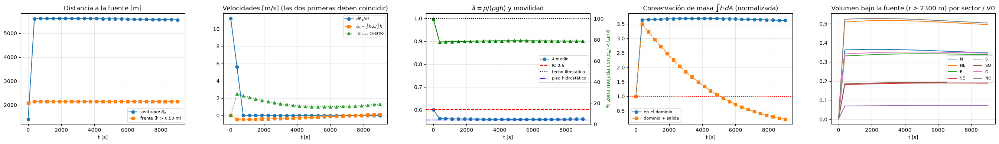

In [13]:
# ============================================================
# 12) DIAGNÓSTICO TEMPORAL: ¿se mueve el lahar, se conserva la masa y por qué flancos baja?
# ============================================================
# [PASO 2] Diagnóstico RADIAL: r = distancia al centro de la fuente (el cráter con DEM;
# (IC_X0, IC_Y0) en los escenarios analíticos).
# Consistencia cinemática: si se conserva la masa y no sale nada por las fronteras,
#   d/dt [ int r h dA ] = int h (u . e_r) dA   =>   dR_c/dt = U_r = (int h u_r dA)/(int h dA)
# Si dR_c/dt >> U_r, el centroide se aleja porque la red CREA masa lejos de la fuente, no
# porque la transporte. La prueba vale mientras no salga masa por las fronteras.
# Reparto por sectores: fracción de V0 que ya bajó de la fuente (r > R_DESC), por octante
# (N, NE, ...). Varios octantes con masa = el lahar baja por varios flancos.
t_check = np.linspace(0.0, Tmax, 25)
cell_area = (xg[1] - xg[0]) * (yg[1] - yg[0])
xs_c, ys_c = (0.0, 0.0) if TOPO_SCENARIO == 4 else (IC_X0, IC_Y0)
dxf, dyf = Xf.ravel() - xs_c, Yf.ravel() - ys_c
Rr = np.hypot(dxf, dyf)
erx, ery = dxf / np.maximum(Rr, 1.0), dyf / np.maximum(Rr, 1.0)      # vector unitario radial
sect_names = ["N", "NE", "E", "SE", "S", "SO", "O", "NO"]
sect_id = (((np.degrees(np.arctan2(dxf, dyf)) % 360.0) + 22.5) // 45.0).astype(int) % 8
R_DESC = SRC_R_OUT + 3.0 * SRC_EDGE_M if TOPO_SCENARIO == 4 else 2.0 * 900.0   # "ya bajó de la fuente"
H_BODY = min(1.0, 0.3 * h0_max)          # espesor que define el cuerpo del lahar [m]
zbx_g, zby_g = grad_zb_fixed(tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf))
tan_f = np.sqrt(zbx_g.numpy()**2 + zby_g.numpy()**2).ravel()

# Puntos de las 4 fronteras (sur, norte, oeste, este) con normal exterior y peso de trapecio
_wx = np.full(nx, xg[1] - xg[0]); _wx[[0, -1]] *= 0.5
_wy = np.full(ny, yg[1] - yg[0]); _wy[[0, -1]] *= 0.5
bx = np.concatenate([xg, xg, np.full(ny, x_min), np.full(ny, x_max)]).astype(np.float32).reshape(-1, 1)
by = np.concatenate([np.full(nx, y_min), np.full(nx, y_max), yg, yg]).astype(np.float32).reshape(-1, 1)
bnx = np.concatenate([np.zeros(nx), np.zeros(nx), -np.ones(ny), np.ones(ny)])
bny = np.concatenate([-np.ones(nx), np.ones(nx), np.zeros(ny), np.zeros(ny)])
bds = np.concatenate([_wx, _wx, _wy, _wy])

cent, Ur, ucore, front, lam_c, lam_gt1, movil, mass, qout, sect_vol = [], [], [], [], [], [], [], [], [], []
for tv in t_check:
    Tf = np.full_like(Xf, tv, dtype=np.float32)
    hp, up, vp, Cp, pp = predict_fields(
        tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf), tf.convert_to_tensor(Tf))
    mu_f = mu_eff(Cp, pp, hp).numpy().ravel()
    hh = hp.numpy().ravel(); uu = up.numpy().ravel()
    vv = vp.numpy().ravel(); pz = pp.numpy().ravel()
    w = np.maximum(hh, 0.0); W = max(w.sum(), 1e-12)
    cent.append(float((Rr * w).sum() / W))                          # R_c: distancia media ponderada por h
    Ur.append(float((w * (uu * erx + vv * ery)).sum() / W))         # U_r: velocidad radial media
    core = hh > H_BODY                                              # cuerpo del lahar (no la película delgada)
    ucore.append(float(np.sqrt(uu[core]**2 + vv[core]**2).max()) if core.any() else 0.0)
    front.append(float(Rr[core].max()) if core.any() else np.nan)   # frente: r máx. del cuerpo
    wet = hh > 0.1
    lam = pz[wet] / (rho_m * g * hh[wet])
    lam_c.append(float(lam.mean()) if wet.any() else np.nan)
    lam_gt1.append(100.0 * float((lam > 1.0).mean()) if wet.any() else np.nan)
    movil.append(100.0 * float((mu_f[wet] < tan_f[wet]).mean()) if wet.any() else np.nan)
    mass.append(float(w.sum() * cell_area))
    sect_vol.append(np.bincount(sect_id, weights=w * (Rr > R_DESC), minlength=8) * cell_area)
    # caudal NETO que sale por las 4 fronteras (se integra en el tiempo más abajo)
    hq, uq, vq, _, _ = predict_fields(tf.constant(bx), tf.constant(by),
                                      tf.constant(np.full_like(bx, tv, dtype=np.float32)))
    qn = hq.numpy().ravel() * (uq.numpy().ravel() * bnx + vq.numpy().ravel() * bny)
    qout.append(float((qn * bds).sum()))

dRc = np.gradient(np.array(cent), t_check)                           # velocidad del centroide radial
# volumen acumulado que salió por las fronteras: masa + salida debe ser constante
vout = np.concatenate([[0.0], np.cumsum(0.5 * (np.array(qout[1:]) + np.array(qout[:-1])) * np.diff(t_check))])
bal = (np.array(mass) + vout) / mass[0]
sect_frac = np.array(sect_vol) / mass[0]                             # (tiempos, 8) en fracción de V0
print(f"{'t [s]':>6} {'R_c [m]':>9} {'dRc/dt':>8} {'U_r':>7} {'|u|cuerpo':>10} {'frente':>8} "
      f"{'lambda':>7} {'%lam>1':>7} {'%movil':>7} {'masa':>7} {'m+sal':>7}")
for k, tv in enumerate(t_check):
    print(f"{tv:6.0f} {cent[k]:9.1f} {dRc[k]:8.2f} {Ur[k]:7.2f} {ucore[k]:10.2f} {front[k]:8.0f} "
          f"{lam_c[k]:7.3f} {lam_gt1[k]:7.1f} {movil[k]:7.1f} {mass[k]/mass[0]:7.3f} {bal[k]:7.3f}")
print(f"  R_c = distancia media a la fuente ponderada por h; dRc/dt, U_r, |u|cuerpo en m/s")
print(f"  frente = r máx. con h > {H_BODY:.2f} m | %movil = zona mojada con mu_eff < tan(theta)")
print("  m+sal = (volumen en el dominio + volumen que salió por las 4 fronteras)/V0: debe ser 1")

idx_show = sorted(set([0, len(t_check) // 4, len(t_check) // 2, 3 * len(t_check) // 4, len(t_check) - 1]))
print(f"\nVolumen que ya bajó de la fuente (r > {R_DESC:.0f} m), por sector, en fracción de V0:")
print(f"{'t [s]':>6} " + " ".join(f"{s:>6}" for s in sect_names) + f" {'salió':>7}")
for k in idx_show:
    print(f"{t_check[k]:6.0f} " + " ".join(f"{f:6.3f}" for f in sect_frac[k]) + f" {vout[k] / mass[0]:7.3f}")

quedan = np.array(mass) / mass[0] > 0.05      # instantes con > 5 % de la masa aún en el dominio
desp = float(np.max(np.array(cent)[quedan]) - cent[0])
pre = vout / mass[0] < 0.01                     # instantes sin salida apreciable por las fronteras
incons = float(np.abs(dRc - np.array(Ur))[pre].mean())
# Flancos activos: sectores donde en algún instante llegó a bajar > 5 % de V0 (la masa puede salir después)
flancos = [s for s, f in zip(sect_names, sect_frac.max(axis=0)) if f > 0.05]
print(f"\n>>> Alejamiento máximo del centroide (con > 5 % de la masa en el dominio): {desp:+.1f} m")
print(f">>> Frente del cuerpo: {front[0]:.0f} m -> {np.nanmax(front):.0f} m de la fuente (máximo en [0, {Tmax:.0f}] s)")
print(f">>> Masa en el dominio: {mass[-1]/mass[0]:.4f} | salió por las fronteras: {vout[-1]/mass[0]:.4f} | balance: {bal[-1]:.4f} (debe ser 1)")
print(f">>> lambda: {lam_c[0]:.3f} (t=0) -> {lam_c[-1]:.3f} (t={Tmax:.0f});  máx. % con lambda>1: {np.nanmax(lam_gt1):.1f}%")
print(f">>> |dRc/dt - U_r| medio antes de que salga masa = {incons:.2f} m/s  (debe ser ~0 si el transporte es físico)")
print(f">>> Sectores donde llegó a bajar > 5 % de V0 en [0, {Tmax:.0f}] s: {', '.join(flancos) if flancos else 'ninguno'}")
if desp < 50.0:
    print("\n*** EL FLUJO SIGUE BLOQUEADO: el centroide casi no se aleja de la fuente. ***")
if np.abs(bal - 1.0).max() > 0.05:
    print("*** LA MASA NO SE CONSERVA (balance con la salida por las fronteras fuera de ±5%). ***")
if incons > 0.5:
    print("*** El centroide NO se mueve con la velocidad del flujo: masa creada/destruida, no transportada. ***")
if np.nanmax(lam_gt1) > 1.0:
    print("*** Hay zona mojada con lambda > 1: la red está apagando la fricción con presión imposible. ***")

fig, axes = plt.subplots(1, 5, figsize=(27, 4))
axes[0].plot(t_check, cent, 'o-', label='centroide $R_c$')
axes[0].plot(t_check, front, 's--', label=f'frente (h > {H_BODY:.2f} m)')
axes[0].set_title("Distancia a la fuente [m]"); axes[0].legend(fontsize=8)
axes[1].plot(t_check, dRc, 'o-', label=r'$dR_c/dt$')
axes[1].plot(t_check, Ur, 's--', label=r'$U_r=\int h u_r/\int h$')
axes[1].plot(t_check, ucore, '^:', label=r'$|u|_{max}$ cuerpo')
axes[1].set_title("Velocidades [m/s] (las dos primeras deben coincidir)"); axes[1].legend(fontsize=8)
axes[2].plot(t_check, lam_c, 'o-', label=r'$\lambda$ medio')
axes[2].axhline(lambda_0, ls='--', c='r', label=f'IC {lambda_0}')
axes[2].axhline(1.0, ls=':', c='k', label='techo litostático')
axes[2].axhline(lambda_hydro, ls='-.', c='b', label='piso hidrostático')
ax2b = axes[2].twinx(); ax2b.plot(t_check, movil, 'g^-', label='% móvil'); ax2b.set_ylim(0, 105)
ax2b.set_ylabel(r'% zona mojada con $\mu_{eff}<\tan\theta$', color='g')
axes[2].set_title(r"$\lambda = p/(\rho g h)$ y movilidad"); axes[2].legend(fontsize=8, loc='center right')
axes[3].plot(t_check, np.array(mass)/mass[0], 'o-', label='en el dominio')
axes[3].plot(t_check, bal, 's--', label='dominio + salida')
axes[3].axhline(1.0, ls=':', c='r'); axes[3].legend(fontsize=8)
axes[3].set_title(r"Conservación de masa $\int h\,dA$ (normalizada)")
for j, s in enumerate(sect_names):
    axes[4].plot(t_check, sect_frac[:, j], '-', lw=1.5, label=s)
axes[4].set_title(f"Volumen bajo la fuente (r > {R_DESC:.0f} m) por sector / V0")
axes[4].legend(fontsize=8, ncol=2)
for a in axes: a.set_xlabel("t [s]"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()


     cauce  km mojados  u_s máx med.  |u| máx med.  en rango  llegada 1er pto
Correntoso        12.2           0.3           1.0       0 %                0
 Pedregoso         7.9           1.3           1.4       0 %              150
    Turbio        12.1           1.6           1.6       0 %              150


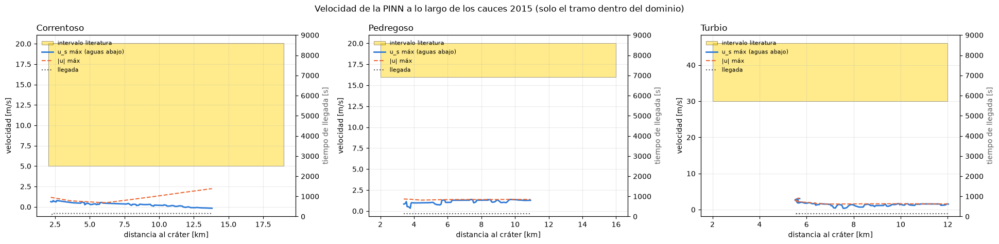

In [14]:
# ============================================================
# 12b) VELOCIDAD EN LOS CAUCES 2015 vs INTERVALOS DE LA LITERATURA  [PASO 3b]
# ============================================================
# A lo largo del eje de cada cauce (solo la parte dentro del dominio), en [0, Tmax]:
#   - u_s máx: máxima componente aguas abajo mientras hay lahar (h > H_VEL_GATE)
#   - |u| máx: máxima rapidez mientras hay lahar
#   - llegada: primer instante con h > H_VEL_GATE (eje derecho)
# La banda amarilla es el intervalo de VEL_INTERVALS. Si la curva queda bajo la banda, la red no
# alcanza la velocidad medida; si no hay curva, el lahar no llegó a ese tramo.
if TOPO_SCENARIO == 4 and RIVERS:
    t_prof = np.linspace(0.0, Tmax, 61).astype(np.float32)
    fig, axes = plt.subplots(1, len(RIVERS), figsize=(6.5 * len(RIVERS), 4.8), squeeze=False)
    print(f"{'cauce':>10} {'km mojados':>11} {'u_s máx med.':>13} {'|u| máx med.':>13} {'en rango':>9} {'llegada 1er pto':>16}")
    for a, (name, R) in zip(axes[0], RIVERS.items()):
        ins = R["inside"]
        if ins.sum() < 2:
            a.set_title(f"{name}: fuera del dominio"); a.set_axis_off(); continue
        xs = R["xy"][ins].astype(np.float32)
        tx, ty, rr = R["t"][ins, 0], R["t"][ins, 1], R["r"][ins]
        n, nt = len(xs), len(t_prof)
        Xc = np.tile(xs[:, 0:1], (nt, 1)); Yc = np.tile(xs[:, 1:2], (nt, 1))
        Tc = np.repeat(t_prof, n).reshape(-1, 1)
        hp, up, vp, _, _ = predict_fields(tf.constant(Xc), tf.constant(Yc), tf.constant(Tc))
        h = hp.numpy().reshape(nt, n); uu = up.numpy().reshape(nt, n); vv = vp.numpy().reshape(nt, n)
        us = uu * tx[None, :] + vv * ty[None, :]
        sp = np.sqrt(uu**2 + vv**2)
        wet = h > H_VEL_GATE
        reached = wet.any(axis=0)
        us_max = np.where(reached, np.where(wet, us, -np.inf).max(axis=0), np.nan)
        sp_max = np.where(reached, np.where(wet, sp, -np.inf).max(axis=0), np.nan)
        t_arr = np.where(reached, t_prof[np.argmax(wet, axis=0)], np.nan)

        segs = VEL_INTERVALS.get(name) or []
        in_rng = np.zeros(n, bool); has_rng = np.zeros(n, bool)
        for k, (r0, r1, v0, v1) in enumerate(segs):
            a.fill_between([r0 / 1e3, r1 / 1e3], v0, v1, color=RIVER_COLOR, alpha=0.45, ec="k", lw=0.6,
                           label="intervalo literatura" if k == 0 else None)
            c = (rr >= r0) & (rr < r1) & reached
            has_rng |= c
            low = us_max if VEL_LOWER == "along" else sp_max
            in_rng |= c & (low >= v0) & (sp_max <= v1)
        a.plot(rr / 1e3, us_max, "-", color="#2a78d6", lw=2, label="u_s máx (aguas abajo)")
        a.plot(rr / 1e3, sp_max, "--", color="#eb6834", lw=1.5, label="|u| máx")
        a.set_xlabel("distancia al cráter [km]"); a.set_ylabel("velocidad [m/s]")
        a.set_title(f"{name}" + ("" if segs else " (sin intervalo)"), loc="left")
        a.grid(alpha=0.25)
        a2 = a.twinx()
        a2.plot(rr / 1e3, t_arr, ":", color="0.35", lw=1.5, label="llegada")
        a2.set_ylabel("tiempo de llegada [s]", color="0.35"); a2.set_ylim(0, Tmax)
        h1, l1 = a.get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels()
        a.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left", frameon=False)
        km_wet = float(np.diff(R["s"], prepend=0.0)[ins][reached].sum() / 1e3)
        pct = f"{100 * in_rng.sum() / has_rng.sum():.0f} %" if has_rng.any() else "-"
        print(f"{name:>10} {km_wet:11.1f} {np.nanmedian(us_max) if reached.any() else np.nan:13.1f} "
              f"{np.nanmedian(sp_max) if reached.any() else np.nan:13.1f} {pct:>9} "
              f"{np.nanmin(t_arr) if reached.any() else np.nan:16.0f}")
    fig.suptitle("Velocidad de la PINN a lo largo de los cauces 2015 (solo el tramo dentro del dominio)")
    plt.tight_layout(); plt.show()
else:
    print("Sin cauces (TOPO_SCENARIO analítico).")


In [15]:
# ============================================================
# 13) ANIMACIÓN: h, |u|, C, lambda
# ============================================================
import matplotlib.animation as animation
from IPython.display import HTML

# BC: fronteras abiertas sin entrada de masa (celda 9). Sin condición sobre C: con
# kappa_C = 0 su ecuación es hiperbólica y no entra flujo por los bordes.
etiqueta = f"5PDE_chi{chi_p:.2f}_kC{kappa_C:.1f}_T{Tmax:.0f}"
if TOPO_SCENARIO == 4:
    etiqueta = f"5PDE_DEM_crater_anillo{SRC_R_IN:.0f}-{SRC_R_OUT:.0f}_chi{chi_p:.2f}_T{Tmax:.0f}"
num_frames = 60
t_values = np.linspace(0.0, Tmax, num_frames)

# Niveles FIJOS. contourf con levels=<int> recalcula los niveles frame a frame
# a partir del rango de los datos e IGNORA vmin/vmax para elegirlos, así que
# la escala de color cambiaba en cada cuadro y la animación era engañosa.
H_PLOT_MAX = min(8.0, max(4.0, 2.5 * h0_max))   # con DEM la fuente es delgada (~H_SRC)
lv_h   = np.linspace(0.0, H_PLOT_MAX, 41)
lv_u   = np.linspace(0.0, 20.0, 41)
lv_C   = np.linspace(0.2, Cmax, 41)
lv_lam = np.linspace(0.0, 1.5, 41)

fig, axes = plt.subplots(2, 2, figsize=(16, 14) if TOPO_SCENARIO == 4 else (16, 9))
fig.suptitle(f"Lahar 5-EDP — {Tmax:.0f} s — "
             rf"$\chi_p$={chi_p}, $\kappa_C$={kappa_C}, $\tau_p$={tau_p:.0f} s")

def update(frame):
    for a in axes.ravel(): a.clear()
    tv = t_values[frame]
    Tf = np.full_like(Xf, tv, dtype=np.float32)
    hp, up, vp, Cp, pp = predict_fields(
        tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf), tf.convert_to_tensor(Tf))

    h_map = hp.numpy().reshape(ny, nx)
    U_map = np.sqrt(up.numpy()**2 + vp.numpy()**2).reshape(ny, nx)
    C_map = Cp.numpy().reshape(ny, nx)
    lam_map = (pp.numpy() / np.maximum(rho_m * g * hp.numpy(), 1e-9)).reshape(ny, nx)

    # Máscara por ESPESOR, no por concentración: C vale ~0.35 de fondo en todo
    # el dominio, así que la máscara antigua (C < 0.01) no se activaba nunca.
    dry = h_map < 0.05
    U_m, C_m, lam_m = (np.ma.masked_where(dry, Z) for Z in (U_map, C_map, lam_map))

    for a in axes.ravel(): a.set_facecolor('lightgrey')
    axes[0, 0].contourf(X, Y, h_map, levels=lv_h, cmap='viridis', extend='max')
    axes[0, 0].set_title(f"Espesor h   t={tv:.0f} s   [m]")
    axes[0, 1].contourf(X, Y, U_m, levels=lv_u, cmap='magma', extend='max')
    axes[0, 1].set_title(f"Velocidad |u|   t={tv:.0f} s   [m/s]")
    axes[1, 0].contourf(X, Y, C_m, levels=lv_C, cmap='plasma', extend='both')
    axes[1, 0].set_title(f"Concentración C   t={tv:.0f} s")
    axes[1, 1].contourf(X, Y, lam_m, levels=lv_lam, cmap='cividis', extend='max')
    axes[1, 1].contour(X, Y, np.ma.masked_where(dry, lam_map), levels=[1.0],
                       colors='r', linewidths=1.5)
    axes[1, 1].set_title(rf"$\lambda = p/(\rho g h)$   t={tv:.0f} s   (rojo: $\lambda=1$)")
    for a in axes.ravel():
        a.contour(X, Y, zb_map, levels=15, colors='k', linewidths=0.4, alpha=0.5)  # curvas de nivel de z_b
        a.set_xlabel(XLAB); a.set_ylabel(YLAB)
        if TOPO_SCENARIO == 4:
            draw_rivers(a, to_utm=False, labels=False, lw=1.4)       # [PASO 3b] cauces 2015
            a.set_xlim(x_min, x_max); a.set_ylim(y_min, y_max)
            a.set_aspect("equal")

print("Generando animación, por favor espera...")
ani = animation.FuncAnimation(fig, update, frames=num_frames, interval=100)
aniname = f"Prediccion {etiqueta}.gif"
ani.save(aniname, writer='pillow', fps=10)
print(f"GIF guardado como '{aniname}'")
plt.close()
display(HTML(ani.to_jshtml()))


Generando animación, por favor espera...
GIF guardado como 'Prediccion 5PDE_DEM_crater_anillo400-2000_chi0.35_T9000.gif'


Animation size has reached 21483620 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


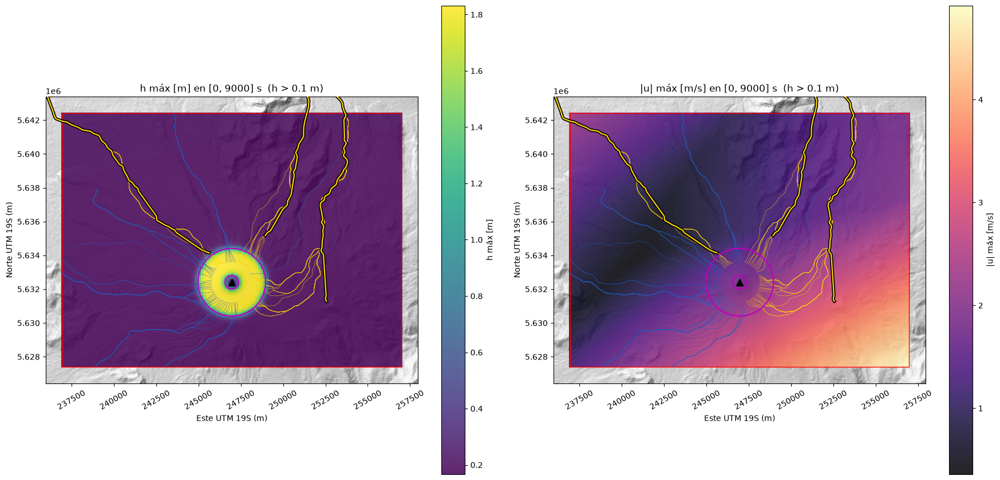

In [16]:
# ============================================================
# 14) MAPA DE INUNDACIÓN SOBRE EL DEM (solo TOPO_SCENARIO = 4)
# ============================================================
# h y |u| máximos en todo [0, Tmax], llevados de vuelta a UTM 19S sobre el relieve.
if TOPO_SCENARIO == 4:
    h_max = np.zeros((ny, nx)); u_max = np.zeros((ny, nx))
    for tv in np.linspace(0.0, Tmax, 41):
        Tf = np.full_like(Xf, tv, dtype=np.float32)
        hp, up, vp, _, _ = predict_fields(
            tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf), tf.convert_to_tensor(Tf))
        h_max = np.maximum(h_max, hp.numpy().reshape(ny, nx))
        u_max = np.maximum(u_max, np.sqrt(up.numpy()**2 + vp.numpy()**2).reshape(ny, nx))
    EG, NG = local_to_utm(X, Y)                     # grilla de evaluación en UTM

    fig, axes = plt.subplots(1, 2, figsize=(18, 8.5))
    for a, Zm, lab, cmap in [(axes[0], h_max, "h máx [m]", "viridis"),
                             (axes[1], u_max, "|u| máx [m/s]", "magma")]:
        a.imshow(hill_dem, cmap="gray", extent=ext_dem)
        pc = a.pcolormesh(EG, NG, np.ma.masked_where(h_max < 0.1, Zm), cmap=cmap,
                          shading="auto", alpha=0.85)
        a.plot(cE, cN, "r-", lw=1)
        for pxy, rr in zip(paths_xy, route_river):   # rutas de máx. pendiente: amarillas a los cauces 2015
            a.plot(*local_to_utm(pxy[:, 0], pxy[:, 1]), "-", color=RIVER_COLOR if rr else ROUTE_COLOR,
                   lw=0.5, alpha=0.7)
        draw_rivers(a, to_utm=True, labels=False, lw=1.6)
        _draw_source(a, to_utm=True)
        a.plot(E_cr, N_cr, "k^", ms=8)
        a.set_xlim(max(cE.min() - 1000, ext_dem[0]), min(cE.max() + 1000, ext_dem[1]))
        a.set_ylim(max(cN.min() - 1000, ext_dem[2]), min(cN.max() + 1000, ext_dem[3]))
        a.set_aspect("equal")
        a.set_xlabel("Este UTM 19S (m)"); a.set_ylabel("Norte UTM 19S (m)")
        a.tick_params(axis="x", labelrotation=30)
        a.set_title(f"{lab} en [0, {Tmax:.0f}] s  (h > 0.1 m)")
        plt.colorbar(pc, ax=a, label=lab)
    plt.tight_layout(); plt.show()


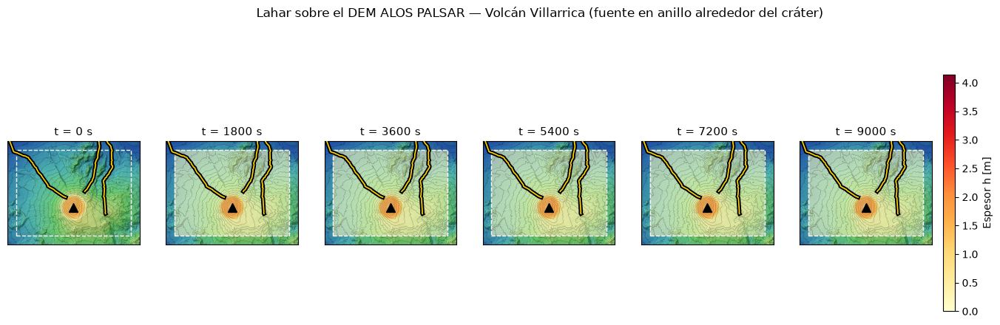

Generando animación sobre el DEM, por favor espera...
GIF guardado como 'Lahar DEM 3D 5PDE_DEM_crater_anillo400-2000_chi0.35_T9000.gif'


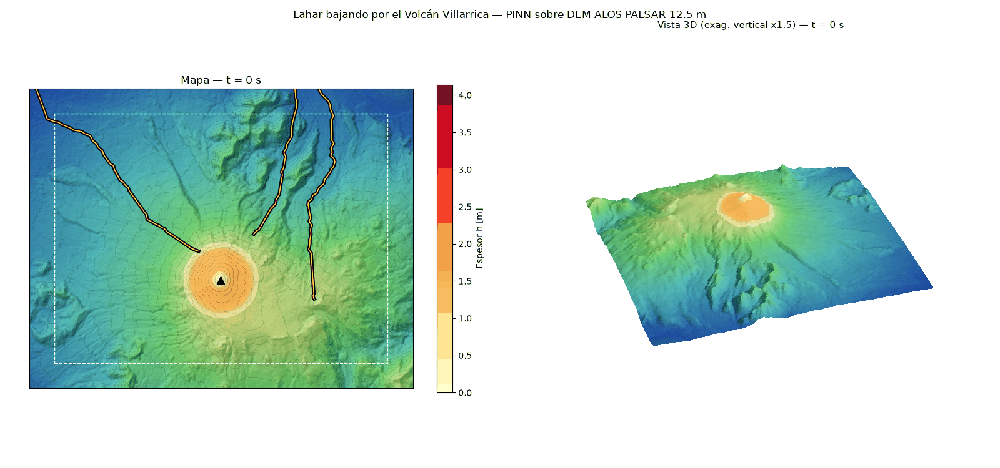

In [17]:
# ============================================================
# 15) LAHAR BAJANDO POR EL VOLCÁN: mapa + vista 3D sobre el DEM (solo TOPO_SCENARIO = 4)
# ============================================================
# La PINN se evalúa directamente en una grilla UTM alineada con el DEM (los puntos que caen
# dentro del dominio centrado en el cráter); fuera del dominio el terreno queda seco.
# Salidas: figura con instantáneas (mapa) y GIF con mapa + vista 3D.
if TOPO_SCENARIO == 4:
    import matplotlib.animation as animation
    from matplotlib.colors import LightSource, Normalize
    from IPython.display import Image, display

    VIS_RES = 30.0        # resolución del mapa [m] (el dominio centrado en el cráter es ~20 x 20 km)
    VIS_RES_3D = 100.0    # resolución de la vista 3D [m] (más fino = más lento)
    VIS_MARGIN = 1500.0   # margen alrededor del dominio y la cumbre [m]
    H_MIN = 0.1           # h mínimo para pintar el lahar [m]
    H_COLOR_MAX = H_PLOT_MAX   # tope de la escala de color de h [m] (celda 13)
    VERT_EXAG = 1.5       # exageración vertical de la vista 3D
    VIEW_ELEV = 35.0      # elevación de la cámara 3D [°]
    VIEW_FROM = 20.0      # rumbo desde donde mira la cámara [°] (20 = desde el NNE, hacia el flanco norte y Pucón)
    N_FRAMES_VIS = 40
    N_SNAPS = 6
    cmap_h = plt.cm.YlOrRd
    norm_h = Normalize(0.0, H_COLOR_MAX)

    # --- Ventana UTM: dominio + cumbre + margen, dentro del DEM ---
    E_lo = max(min(cE.min(), E_cr) - VIS_MARGIN, ext_dem[0])
    E_hi = min(max(cE.max(), E_cr) + VIS_MARGIN, ext_dem[1])
    N_lo = max(min(cN.min(), N_cr) - VIS_MARGIN, ext_dem[2])
    N_hi = min(max(cN.max(), N_cr) + VIS_MARGIN, ext_dem[3])

    def vis_grid(res):
        """Grilla UTM (filas de norte a sur), cota del DEM y coordenadas locales de cada punto."""
        Ev = np.arange(E_lo + res / 2, E_hi, res)
        Nv = np.arange(N_hi - res / 2, N_lo, -res)
        EE, NN = np.meshgrid(Ev, Nv)
        zz = dem_sample(dem, EE, NN)
        xl, yl = utm_to_local(EE, NN)
        inside = (xl >= x_min) & (xl <= x_max) & (yl >= y_min) & (yl <= y_max)
        return EE, NN, zz, xl.astype(np.float32), yl.astype(np.float32), inside

    _CHUNK = 32768   # tamaño fijo de lote: evita re-trazar predict_fields en cada llamada
    def h_on_grid(xl, yl, inside, tv):
        """h de la PINN en los puntos 'inside' de la grilla, en el instante tv; 0 fuera."""
        xs, ys = xl[inside], yl[inside]
        out = np.empty(xs.size, np.float32)
        for i in range(0, xs.size, _CHUNK):
            n = min(_CHUNK, xs.size - i)
            xb = np.zeros((_CHUNK, 1), np.float32); yb = np.zeros((_CHUNK, 1), np.float32)
            xb[:n, 0], yb[:n, 0] = xs[i:i + n], ys[i:i + n]
            hb, _, _, _, _ = predict_fields(tf.constant(xb), tf.constant(yb),
                                            tf.constant(np.full((_CHUNK, 1), tv, np.float32)))
            out[i:i + n] = hb.numpy()[:n, 0]
        h = np.zeros(xl.shape, np.float32)
        h[inside] = out
        return h

    ls = LightSource(azdeg=315, altdeg=45)
    def base_rgb(zz, res):
        """Relieve sombreado con tinte hipsométrico suave (RGBA)."""
        rgb = ls.shade(zz, cmap=plt.cm.gist_earth, blend_mode="soft", vert_exag=2,
                       dx=res, dy=res, vmin=zz.min() - 300, vmax=zz.max() + 300)
        return rgb

    def blend_lahar(rgb, h):
        """Pinta el lahar (h > H_MIN) sobre el relieve; opacidad crece con h."""
        out = rgb.copy()
        wet = h > H_MIN
        a = np.clip(0.55 + 0.45 * h / H_COLOR_MAX, 0.0, 1.0)[..., None]
        out[wet] = (1 - a[wet]) * rgb[wet] + a[wet] * cmap_h(norm_h(h[wet]))
        return out

    EE, NN, zz, xl, yl, inside = vis_grid(VIS_RES)
    EE3, NN3, zz3, xl3, yl3, inside3 = vis_grid(VIS_RES_3D)
    rgb_map, rgb_3d = base_rgb(zz, VIS_RES), base_rgb(zz3, VIS_RES_3D)
    ext_vis = (EE[0, 0] - VIS_RES / 2, EE[0, -1] + VIS_RES / 2, NN[-1, 0] - VIS_RES / 2, NN[0, 0] + VIS_RES / 2)
    lev_z = np.arange(0, 3000, 100)

    def draw_map(ax, h, tv):
        ax.imshow(blend_lahar(rgb_map, h), extent=ext_vis, interpolation="bilinear")
        ax.contour(EE, NN, zz, levels=lev_z, colors="k", linewidths=0.25, alpha=0.4)
        ax.plot(cE, cN, "w--", lw=1)
        draw_rivers(ax, to_utm=True, labels=False, lw=1.2)   # [PASO 3b] cauces 2015
        ax.plot(E_cr, N_cr, "k^", ms=8)
        ax.set_xlim(ext_vis[:2]); ax.set_ylim(ext_vis[2:])
        ax.set_title(f"t = {tv:.0f} s", fontsize=11)
        ax.set_xticks([]); ax.set_yticks([])

    # --- (a) Instantáneas en mapa ---
    t_snaps = np.linspace(0.0, Tmax, N_SNAPS)
    fig, axes = plt.subplots(1, N_SNAPS, figsize=(3.2 * N_SNAPS, 5.2))
    for a, tv in zip(axes, t_snaps):
        draw_map(a, h_on_grid(xl, yl, inside, tv), tv)
    fig.colorbar(plt.cm.ScalarMappable(norm=norm_h, cmap=cmap_h), ax=axes, shrink=0.8,
                 label="Espesor h [m]", pad=0.01)
    fig.suptitle("Lahar sobre el DEM ALOS PALSAR — Volcán Villarrica (fuente en anillo alrededor del cráter)")
    plt.show()

    # --- (b) Animación: mapa + vista 3D ---
    fig = plt.figure(figsize=(16, 7.5))
    ax_m = fig.add_subplot(1, 2, 1)
    ax_3 = fig.add_subplot(1, 2, 2, projection="3d")
    fig.colorbar(plt.cm.ScalarMappable(norm=norm_h, cmap=cmap_h), ax=ax_m, shrink=0.75, label="Espesor h [m]")

    surf = ax_3.plot_surface(EE3, NN3, zz3 * VERT_EXAG, facecolors=rgb_3d, rstride=1, cstride=1,
                             linewidth=0, antialiased=False, shade=False)
    ax_3.view_init(elev=VIEW_ELEV, azim=90.0 - VIEW_FROM)
    ax_3.set_box_aspect((np.ptp(EE3), np.ptp(NN3), VERT_EXAG * np.ptp(zz3)))
    ax_3.set_axis_off()
    title_3d = ax_3.set_title("", fontsize=11)

    def update_vis(frame):
        tv = t_vis[frame]
        ax_m.clear()
        draw_map(ax_m, h_on_grid(xl, yl, inside, tv), tv)
        ax_m.set_title(f"Mapa — t = {tv:.0f} s")
        h3 = h_on_grid(xl3, yl3, inside3, tv)
        # plot_surface usa el color de la esquina superior izquierda de cada celda, fila por fila
        surf.set_facecolor(blend_lahar(rgb_3d, h3)[:-1, :-1].reshape(-1, 4))
        title_3d.set_text(f"Vista 3D (exag. vertical x{VERT_EXAG:g}) — t = {tv:.0f} s")
        return []

    t_vis = np.linspace(0.0, Tmax, N_FRAMES_VIS)
    fig.suptitle("Lahar bajando por el Volcán Villarrica — PINN sobre DEM ALOS PALSAR 12.5 m")
    plt.tight_layout()
    print("Generando animación sobre el DEM, por favor espera...")
    ani_vis = animation.FuncAnimation(fig, update_vis, frames=N_FRAMES_VIS, interval=150)
    gif_vis = f"Lahar DEM 3D {etiqueta}.gif"
    ani_vis.save(gif_vis, writer="pillow", fps=8)
    plt.close(fig)
    print(f"GIF guardado como '{gif_vis}'")
    display(Image(filename=gif_vis))
else:
    print("TOPO_SCENARIO analítico: esta figura necesita el DEM (TOPO_SCENARIO = 4).")


In [18]:
xb, yb, tb = sample_pde_batch()
f = pde_residuals(xb, yb, tb); h = predict_fields(xb, yb, tb)[0].numpy().ravel()
sc = [h_scale/t_scale, 0.1*g*S_ref, 0.1*g*S_ref, Cmax/t_scale, p_scale/t_scale]
wet = h > 0.1
for n, fi, s in zip(["masa","mom_x","mom_y","C","p"], f, sc):
    r2 = (fi.numpy().ravel()/s)**2
    print(f"{n:6s} total {r2.mean():.3e} | mojado {r2[wet].mean():.3e} | seco {r2[~wet].mean():.3e}")
print("fracción mojada:", wet.mean())

masa   total 1.535e+00 | mojado 5.720e-01 | seco 2.778e+01
mom_x  total 9.256e+02 | mojado 9.357e+02 | seco 6.505e+02
mom_y  total 8.570e+02 | mojado 8.594e+02 | seco 7.928e+02
C      total 9.930e+00 | mojado 3.367e+00 | seco 1.888e+02
p      total 6.357e-01 | mojado 3.468e-01 | seco 8.508e+00
fracción mojada: 0.964599609375
